### **Part A – Representation Learning**

#### Step 1 – Introduction

The objective of this section is to investigate hidden patterns in multivariate train sensor data using representation learning techniques. Principal Component Analysis, a linear Autoencoder and a Self-Organising Map are implemented to reduce dimensionality and identify operational patterns that may be associated with mechanical faults.

#### Step 2 – Install libraries

In [1]:
!pip install minisom -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


#### Step 3 – Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Input, Dense, SimpleRNN, LSTM
from tensorflow.keras.callbacks import EarlyStopping
from minisom import MiniSom
from google.colab import files

np.random.seed(42)
tf.random.set_seed(42)

#### Step 4 – Upload the train dataset

In [3]:
uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
df.head()

Saving MetroPT3(AirCompressor).csv to MetroPT3(AirCompressor).csv
Dataset shape: (1516948, 17)


,Unnamed: 0,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,10,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,20,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,30,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,40,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


#### Step 5 – Dataset exploration

In [5]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1516948 entries, 0 to 1516947
Data columns (total 17 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   Unnamed: 0       1516948 non-null  int64  
 1   timestamp        1516948 non-null  object 
 2   TP2              1516948 non-null  float64
 3   TP3              1516948 non-null  float64
 4   H1               1516948 non-null  float64
 5   DV_pressure      1516948 non-null  float64
 6   Reservoirs       1516948 non-null  float64
 7   Oil_temperature  1516948 non-null  float64
 8   Motor_current    1516948 non-null  float64
 9   COMP             1516948 non-null  float64
 10  DV_eletric       1516948 non-null  float64
 11  Towers           1516948 non-null  float64
 12  MPG              1516948 non-null  float64
 13  LPS              1516948 non-null  float64
 14  Pressure_switch  1516948 non-null  float64
 15  Oil_level        1516948 non-null  float64
 16  Caudal_impulses  1

,Unnamed: 0,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
count,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06
mean,7.584735e+06,1.367826e+00,8.984611e+00,7.568155e+00,5.595619e-02,8.985233e+00,6.264418e+01,2.050171e+00,8.369568e-01,1.606106e-01,9.198483e-01,8.326640e-01,3.420025e-03,9.914368e-01,9.041556e-01,9.371066e-01
std,4.379053e+06,3.250930e+00,6.390951e-01,3.333200e+00,3.824015e-01,6.383070e-01,6.516261e+00,2.302053e+00,3.694052e-01,3.671716e-01,2.715280e-01,3.732757e-01,5.838091e-02,9.214078e-02,2.943779e-01,2.427712e-01
min,0.000000e+00,-3.200000e-02,7.300000e-01,-3.600000e-02,-3.200000e-02,7.120000e-01,1.540000e+01,2.000000e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.792368e+06,-1.400000e-02,8.492000e+00,8.254000e+00,-2.200000e-02,8.494000e+00,5.777500e+01,4.000000e-02,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
50%,7.584735e+06,-1.200000e-02,8.960000e+00,8.784000e+00,-2.000000e-02,8.960000e+00,6.270000e+01,4.500000e-02,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
75%,1.137710e+07,-1.000000e-02,9.492000e+00,9.374000e+00,-1.800000e-02,9.492000e+00,6.725000e+01,3.807500e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
max,1.516947e+07,1.067600e+01,1.030200e+01,1.028800e+01,9.844000e+00,1.030000e+01,8.905000e+01,9.295000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


#### Step 6 – Data cleaning

In [6]:
df = df.drop_duplicates().copy()

df = df.loc[:, ~df.columns.str.startswith('Unnamed')]

if 'timestamp' in df.columns:
    df['timestamp'] = pd.to_datetime(
        df['timestamp'], errors='coerce'
    )
    df = df.sort_values('timestamp')

df = df.dropna()

sensor_df = df.select_dtypes(include=np.number)

sensor_df = sensor_df.loc[
    :, sensor_df.nunique() > 1
]

print("Cleaned data:", sensor_df.shape)
display(sensor_df.head())

Cleaned data: (1516948, 15)


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


#### Step 7 – Exploratory Data Analysis

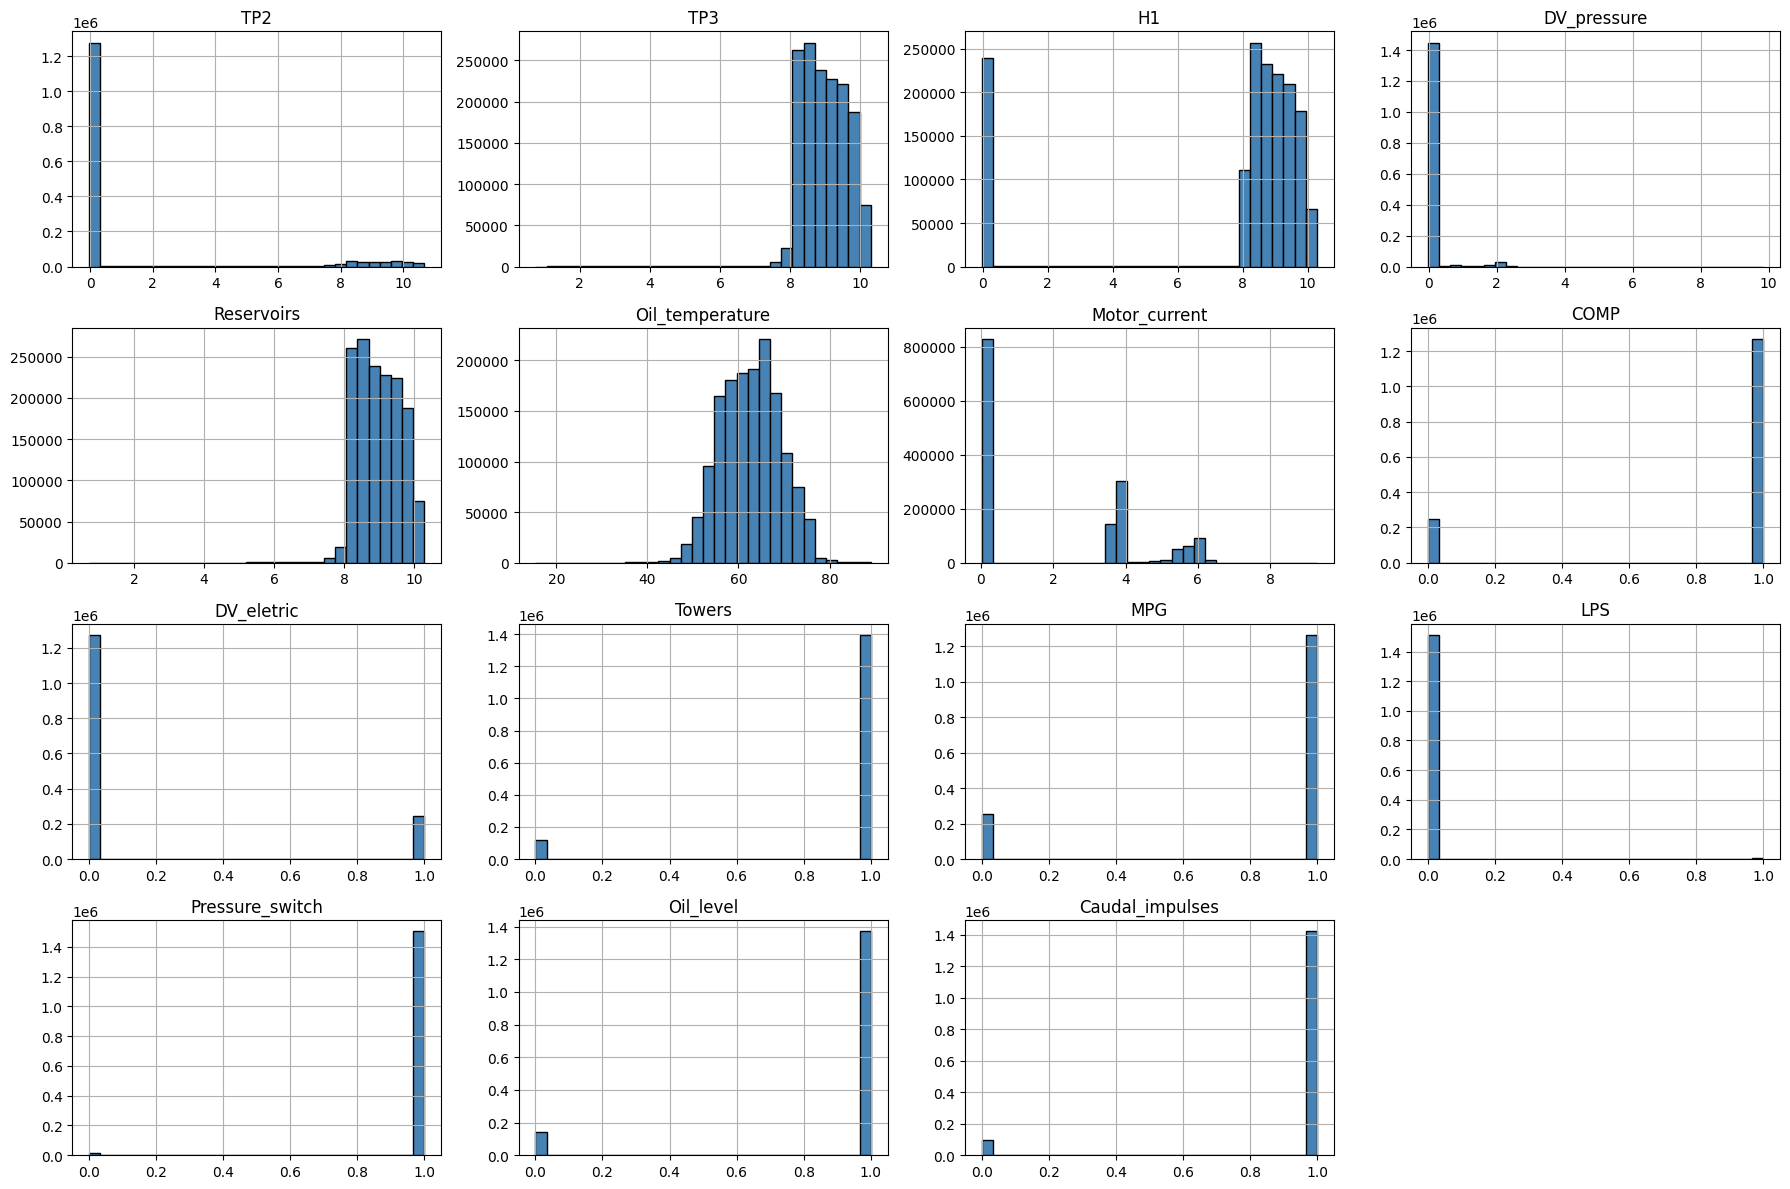

In [7]:
# Sensor distributions

sensor_df.hist(
    figsize=(18, 12),
    bins=30,
    color='steelblue',
    edgecolor='black'
)

plt.tight_layout()
plt.show()

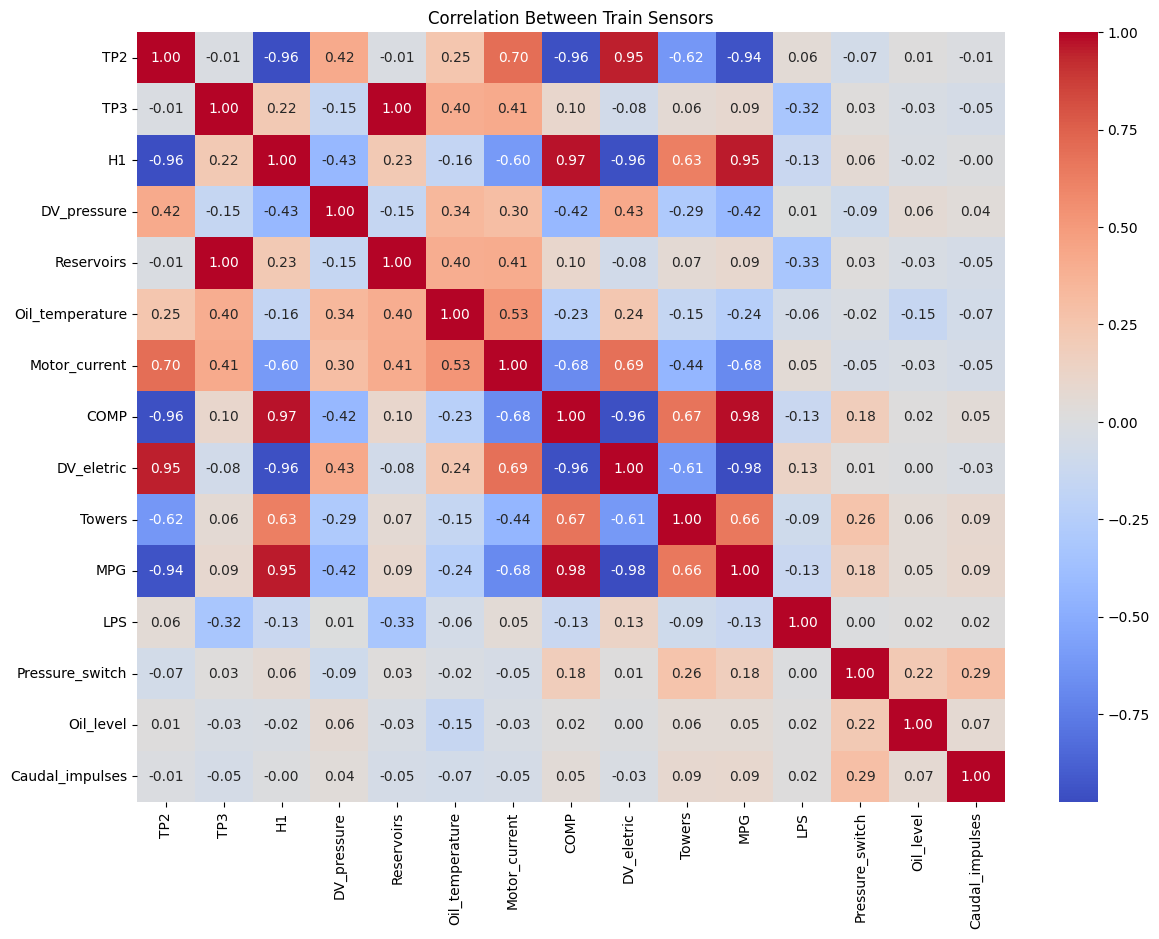

In [8]:
# Correlation heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    sensor_df.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title("Correlation Between Train Sensors")
plt.show()

#### Step 8 – Sampling and standardisation

In [9]:
sample_df = sensor_df.sample(
    n=min(50000, len(sensor_df)),
    random_state=42
)

X_train_raw, X_test_raw = train_test_split(
    sample_df,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (40000, 15)
Testing data: (10000, 15)


#### Step 9 – Apply PCA

In [10]:
pca = PCA(n_components=2)

X_pca_train = pca.fit_transform(X_train)
X_pca_test = pca.transform(X_test)

print("Explained variance:")
print(pca.explained_variance_ratio_)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

Explained variance:
[0.41307676 0.17835959]
Total explained variance: 0.5914363450142233


#### Step 10 – Visualise PCA

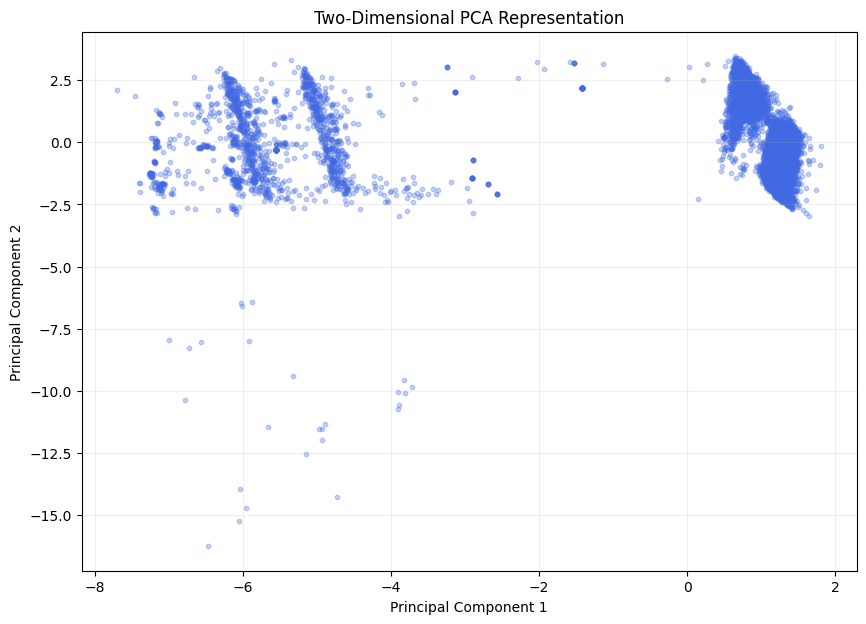

In [11]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca_test[:, 0],
    X_pca_test[:, 1],
    alpha=0.3,
    s=10,
    color='royalblue'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Two-Dimensional PCA Representation")
plt.grid(alpha=0.2)
plt.show()

#### Step 11 – Explained variance graph

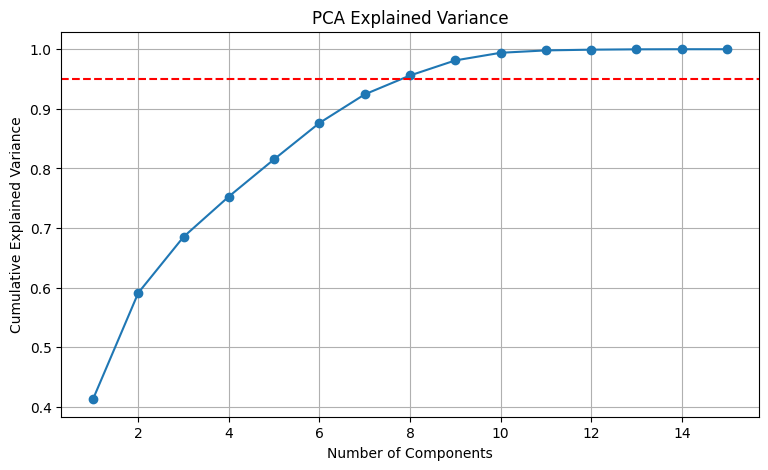

In [12]:
pca_full = PCA()
pca_full.fit(X_train)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, X_train.shape[1] + 1),
    np.cumsum(pca_full.explained_variance_ratio_),
    marker='o'
)

plt.axhline(0.95, color='red', linestyle='--')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid()
plt.show()

#### Step 12 – PCA reconstruction error

In [13]:
pca_reconstruction = pca.inverse_transform(
    X_pca_test
)

pca_mse = mean_squared_error(
    X_test,
    pca_reconstruction
)

print("PCA Reconstruction MSE:", pca_mse)

PCA Reconstruction MSE: 0.3880699276567124


#### Step 13 – Build the linear Autoencoder

In [14]:
input_dim = X_train.shape[1]

input_layer = Input(shape=(input_dim,))

encoded = Dense(
    2,
    activation='linear',
    name='latent_space'
)(input_layer)

decoded = Dense(
    input_dim,
    activation='linear'
)(encoded)

autoencoder = Model(input_layer, decoded)

encoder = Model(input_layer, encoded)

autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 15)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 2)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │            45 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77 (308.00 B)

 Trainable params: 77 (308.00 B)

 Non-trainable params: 0 (0.00 B)

#### Step 14 – Train the model

In [15]:
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=30,
    batch_size=128,
    validation_split=0.2,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=10,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.9569 - val_loss: 0.7755
Epoch 2/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6227 - val_loss: 0.5274
Epoch 3/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4778 - val_loss: 0.4578
Epoch 4/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4316 - val_loss: 0.4323
Epoch 5/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4155 - val_loss: 0.4232
Epoch 6/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4102 - val_loss: 0.4199
Epoch 7/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4084 - val_loss: 0.4185
Epoch 8/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4078 - val_loss: 0.4179
Epoch 9/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4075 - val_loss: 0.4175
Epoch 10/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4074 - val_loss: 0.4173
Epoch 11/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4073 - val_loss: 0.4171
Epoch 12/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

#### Step 15 – Training and validation loss

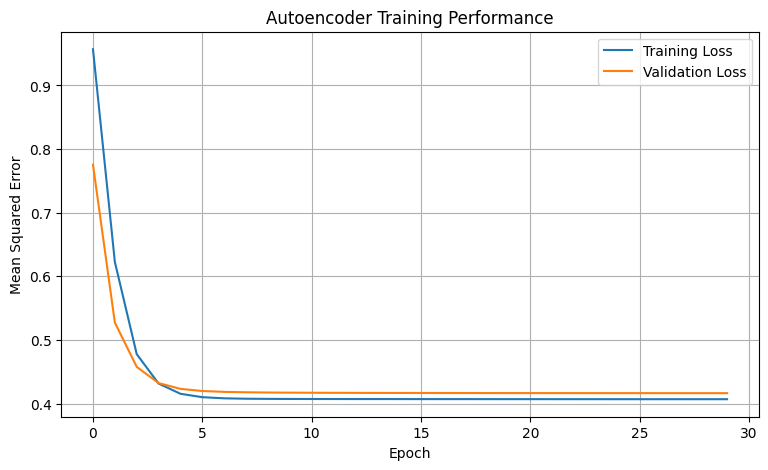

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Autoencoder Training Performance")
plt.legend()
plt.grid()
plt.show()

#### Step 16 – Visualise the latent representation

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


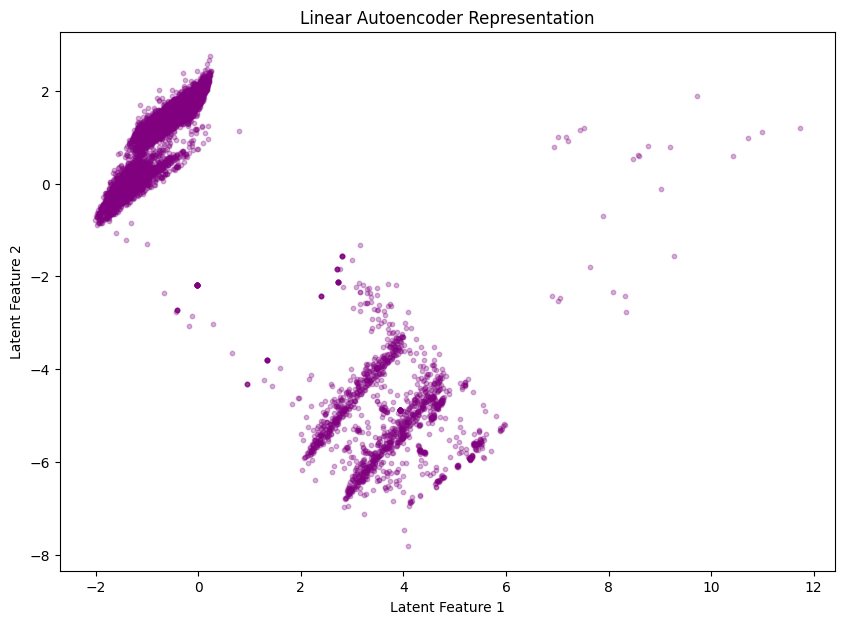

In [17]:
X_encoded = encoder.predict(X_test)

plt.figure(figsize=(10, 7))

plt.scatter(
    X_encoded[:, 0],
    X_encoded[:, 1],
    color='purple',
    alpha=0.3,
    s=10
)

plt.xlabel("Latent Feature 1")
plt.ylabel("Latent Feature 2")
plt.title("Linear Autoencoder Representation")
plt.show()

#### Step 17 – Autoencoder reconstruction error

In [18]:
X_reconstructed = autoencoder.predict(X_test)

ae_mse = mean_squared_error(
    X_test,
    X_reconstructed
)

print("Autoencoder Reconstruction MSE:", ae_mse)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Autoencoder Reconstruction MSE: 0.3887508848107589


#### Step 18 – Compare PCA and Autoencoder

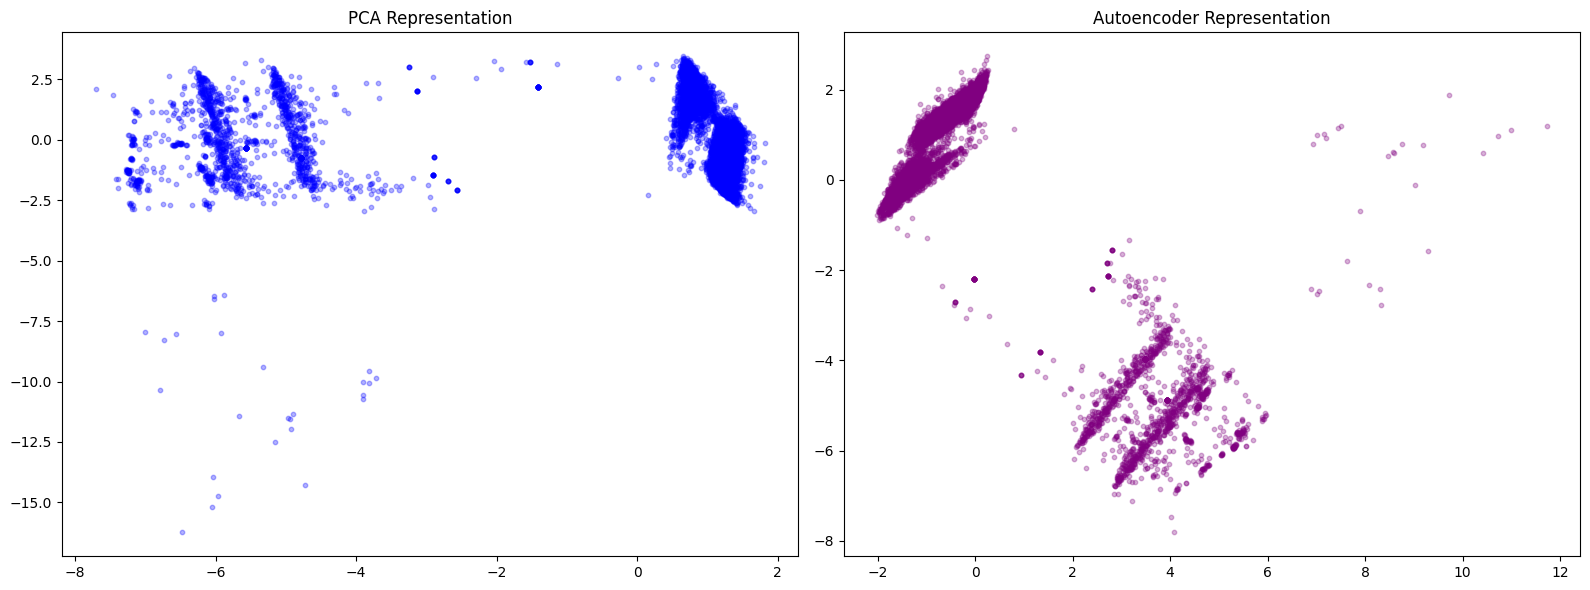

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(
    X_pca_test[:, 0],
    X_pca_test[:, 1],
    alpha=0.3,
    s=10,
    color='blue'
)

axes[0].set_title("PCA Representation")

axes[1].scatter(
    X_encoded[:, 0],
    X_encoded[:, 1],
    alpha=0.3,
    s=10,
    color='purple'
)

axes[1].set_title("Autoencoder Representation")

plt.tight_layout()
plt.show()

,Model,Reconstruction MSE
0,PCA,0.388070
1,Linear Autoencoder,0.388751


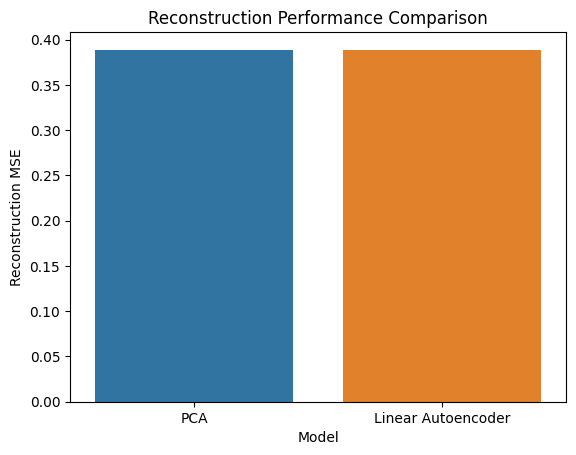

In [20]:
comparison = pd.DataFrame({
    'Model': ['PCA', 'Linear Autoencoder'],
    'Reconstruction MSE': [pca_mse, ae_mse]
})

display(comparison)

sns.barplot(
    data=comparison,
    x='Model',
    y='Reconstruction MSE',
    hue='Model',
    legend=False
)

plt.title("Reconstruction Performance Comparison")
plt.show()

#### Step 19 – Build and train SOM

In [21]:
som = MiniSom(
    x=10,
    y=10,
    input_len=X_train.shape[1],
    sigma=1.5,
    learning_rate=0.5,
    random_seed=42
)

som.random_weights_init(X_train)

som.train_random(
    X_train,
    num_iteration=10000,
    verbose=True
)

 [ 10000 / 10000 ] 100% - 0:00:00 left 
 quantization error: 0.5067207906773991


#### Step 20 – Visualise SOM

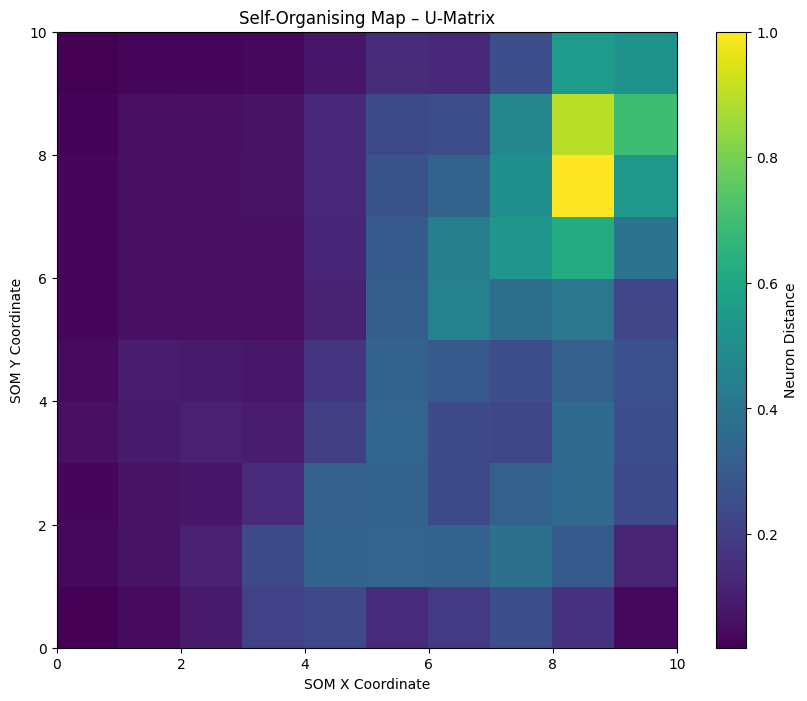

In [22]:
plt.figure(figsize=(10, 8))

plt.pcolor(
    som.distance_map().T,
    cmap='viridis'
)

plt.colorbar(label='Neuron Distance')
plt.title("Self-Organising Map – U-Matrix")
plt.xlabel("SOM X Coordinate")
plt.ylabel("SOM Y Coordinate")
plt.show()

#### Step 21 – SOM activation map

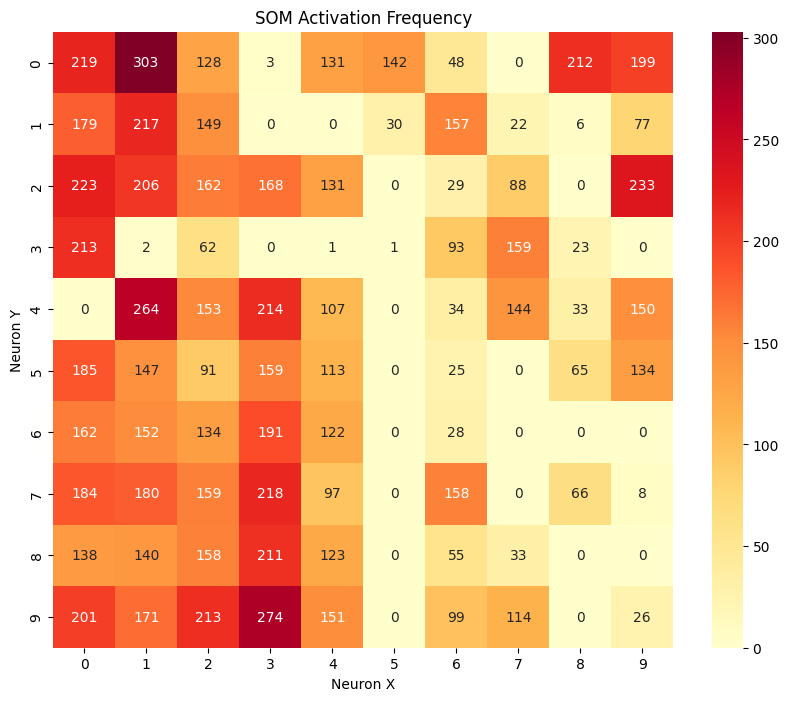

Quantization Error: 0.4918530480634052


In [23]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    som.activation_response(X_test).T,
    cmap='YlOrRd',
    annot=True,
    fmt='.0f'
)

plt.title("SOM Activation Frequency")
plt.xlabel("Neuron X")
plt.ylabel("Neuron Y")
plt.show()

print(
    "Quantization Error:",
    som.quantization_error(X_test)
)

#### Step 22 – Identify unusual sensor observations

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Anomaly threshold: 1.1692299165971807
Potential anomalies: 473


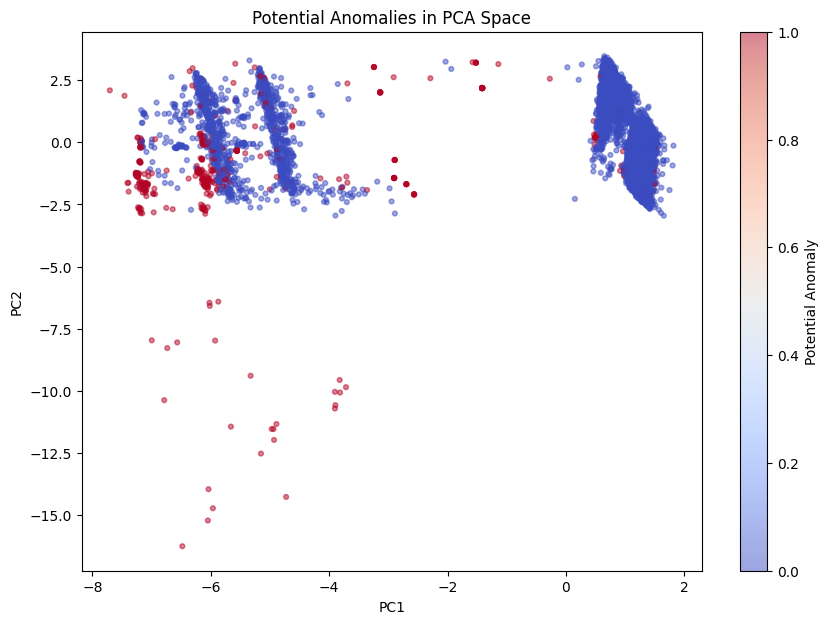

In [24]:
reconstruction_errors = np.mean(
    (X_test - X_reconstructed) ** 2,
    axis=1
)

train_reconstructed = autoencoder.predict(X_train)

train_errors = np.mean(
    (X_train - train_reconstructed) ** 2,
    axis=1
)

threshold = np.percentile(train_errors, 95)

anomalies = reconstruction_errors > threshold

print("Anomaly threshold:", threshold)
print("Potential anomalies:", anomalies.sum())

plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca_test[:, 0],
    X_pca_test[:, 1],
    c=anomalies.astype(int),
    cmap='coolwarm',
    alpha=0.5,
    s=12
)

plt.colorbar(label='Potential Anomaly')
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Potential Anomalies in PCA Space")
plt.show()

#### Step 23 – Part A Discussion

The MetroPT-3 dataset was analysed using PCA, a Linear
Autoencoder and a Self-Organising Map (SOM).

PCA reduced 15 sensor features into two principal
components while retaining 59.14% of the original variance.

PCA achieved a reconstruction MSE of 0.388070, while
the Linear Autoencoder achieved an MSE of 0.388751.
The similar reconstruction errors demonstrate that both
linear methods provide comparable dimensionality reduction
performance.

The SOM achieved a testing quantisation error of 0.491853
and provided an additional approach for visualising groups
of similar sensor observations.

The anomaly detection analysis identified 473 potential
anomalies, representing 4.73% of the testing observations.

These observations may represent unusual operating
conditions. However, they cannot be confirmed as mechanical
faults without actual failure and maintenance records.

Overall, the representation learning methods demonstrate
the potential to identify hidden operational patterns
within multivariate train sensor data.

### **PART B – SEQUENCE LEARNING (AIRCRAFT)**

#### Step 1 – Introduction and Track Selection

For Part B, Track 2 – Recurrent Neural Networks (Aircraft) was selected to investigate predictive maintenance using aircraft engine time-series data.

The objective is to predict the Remaining Useful Life (RUL) of aircraft engines using historical sensor measurements.

Two deep learning models are implemented:

- Simple Recurrent Neural Network (RNN)
- Long Short-Term Memory (LSTM)

Track 2 was selected because aircraft engines generate sequential sensor measurements throughout their operational life. Recurrent neural networks are suitable for learning temporal dependencies and identifying engine degradation patterns.

The performance of both models is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

#### Step 2 – Import Required Libraries

In [25]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    SimpleRNN,
    LSTM,
    Dropout
)

from tensorflow.keras.callbacks import EarlyStopping

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


#### Step 3 – Connect Google Drive

In [26]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### Step 4 – Access the Dataset Folder

In [27]:
dataset_path = "/content/drive/MyDrive/Air_Craft"

print("Available dataset files:\n")

for file in os.listdir(dataset_path):
    print(file)

Available dataset files:

Damage Propagation Modeling.pdf
readme.txt
RUL_FD001.txt
RUL_FD002.txt
RUL_FD003.txt
RUL_FD004.txt
test_FD001.txt
test_FD002.txt
test_FD003.txt
test_FD004.txt
train_FD001.txt
train_FD002.txt
train_FD003.txt
train_FD004.txt


#### Step 5 – Dataset Description and Loading

In [28]:
columns = [
    'unit_number',
    'time_cycles',
    'setting_1',
    'setting_2',
    'setting_3'
] + [f'sensor_{i}' for i in range(1, 22)]

# Training dataset
train_df = pd.read_csv(
    os.path.join(dataset_path, 'train_FD001.txt'),
    sep=r'\s+',
    header=None,
    names=columns
)

# Testing dataset
test_df = pd.read_csv(
    os.path.join(dataset_path, 'test_FD001.txt'),
    sep=r'\s+',
    header=None,
    names=columns
)

# Actual Remaining Useful Life
rul_df = pd.read_csv(
    os.path.join(dataset_path, 'RUL_FD001.txt'),
    sep=r'\s+',
    header=None,
    names=['RUL']
)

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)
print("RUL dataset shape:", rul_df.shape)

Training dataset shape: (20631, 26)
Testing dataset shape: (13096, 26)
RUL dataset shape: (100, 1)


#### Step 6 – Initial Dataset Exploration

In [29]:
print("Training Dataset:")
display(train_df.head())

print("\nTesting Dataset:")
display(test_df.head())

print("\nRemaining Useful Life Dataset:")
display(rul_df.head())

print("\nDataset Information:")
train_df.info()

print("\nDescriptive Statistics:")
display(train_df.describe())

Training Dataset:


,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044



Testing Dataset:


,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130



Remaining Useful Life Dataset:


,RUL
0,112
1,98
2,69
3,82
4,91



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   unit_number  20631 non-null  int64  
 1   time_cycles  20631 non-null  int64  
 2   setting_1    20631 non-null  float64
 3   setting_2    20631 non-null  float64
 4   setting_3    20631 non-null  float64
 5   sensor_1     20631 non-null  float64
 6   sensor_2     20631 non-null  float64
 7   sensor_3     20631 non-null  float64
 8   sensor_4     20631 non-null  float64
 9   sensor_5     20631 non-null  float64
 10  sensor_6     20631 non-null  float64
 11  sensor_7     20631 non-null  float64
 12  sensor_8     20631 non-null  float64
 13  sensor_9     20631 non-null  float64
 14  sensor_10    20631 non-null  float64
 15  sensor_11    20631 non-null  float64
 16  sensor_12    20631 non-null  float64
 17  sensor_13    20631 non-null  float64
 18  sensor_14    20631 non-n

,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,2.063100e+04,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,5.186700e+02,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,6.537152e-11,0.500053,6.131150,9.000605,3.394700e-12,...,0.737553,0.071919,19.076176,0.037505,1.556432e-14,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,5.186700e+02,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,5.186700e+02,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,5.186700e+02,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,5.186700e+02,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,5.186700e+02,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


#### Step 7 – Data Quality Assessment

In [30]:
quality_summary = pd.DataFrame({
    'Dataset': ['Training', 'Testing', 'RUL'],

    'Missing Values': [
        train_df.isnull().sum().sum(),
        test_df.isnull().sum().sum(),
        rul_df.isnull().sum().sum()
    ],

    'Duplicate Rows': [
        train_df.duplicated().sum(),
        test_df.duplicated().sum(),
        rul_df.duplicated().sum()
    ],

    'Infinite Values': [
        np.isinf(train_df.to_numpy()).sum(),
        np.isinf(test_df.to_numpy()).sum(),
        np.isinf(rul_df.to_numpy()).sum()
    ]
})

display(quality_summary)

print("Training engines:",
      train_df['unit_number'].nunique())

print("Testing engines:",
      test_df['unit_number'].nunique())

,Dataset,Missing Values,Duplicate Rows,Infinite Values
0,Training,0,0,0
1,Testing,0,0,0
2,RUL,0,29,0


Training engines: 100
Testing engines: 100


#### Step 8 – Data Cleaning

In [31]:
train_df = train_df.drop_duplicates().copy()
test_df = test_df.drop_duplicates().copy()

train_df = train_df.sort_values(
    ['unit_number', 'time_cycles']
).reset_index(drop=True)

test_df = test_df.sort_values(
    ['unit_number', 'time_cycles']
).reset_index(drop=True)

assert np.isfinite(train_df.to_numpy()).all()
assert np.isfinite(test_df.to_numpy()).all()
assert np.isfinite(rul_df.to_numpy()).all()

assert len(rul_df) == test_df['unit_number'].nunique()

print("Data cleaning completed.")
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

Data cleaning completed.
Training dataset: (20631, 26)
Testing dataset: (13096, 26)


#### Step 9 - Exploratory Data Analysis (EDA)

In [32]:
# Calculate Remaining Useful Life

max_cycles = train_df.groupby(
    'unit_number'
)['time_cycles'].transform('max')

train_df['RUL'] = (
    max_cycles - train_df['time_cycles']
)

print("RUL calculation completed.")

display(
    train_df[
        ['unit_number', 'time_cycles', 'RUL']
    ].head(10)
)

RUL calculation completed.


,unit_number,time_cycles,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182


#### Step 10 – Distribution of Engine Operational Lifetimes

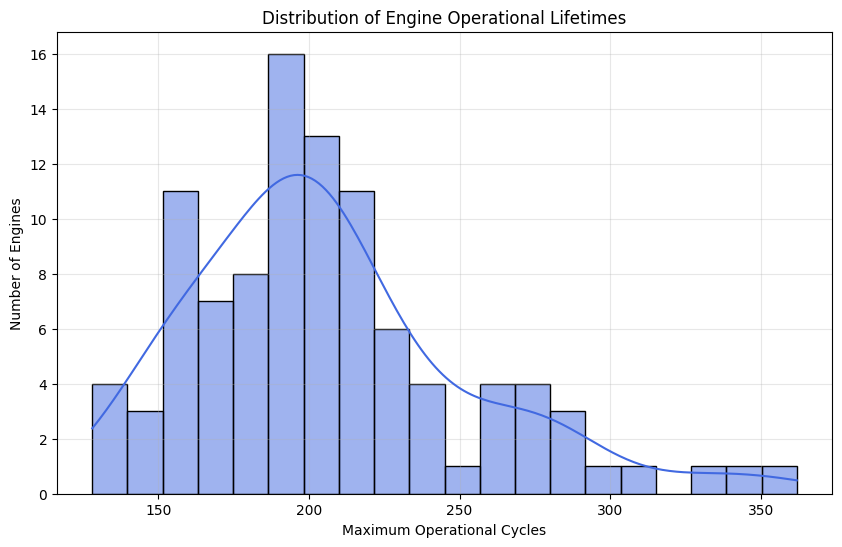

Minimum lifetime: 128
Maximum lifetime: 362
Average lifetime: 206.31


In [33]:
engine_lifetime = train_df.groupby(
    'unit_number'
)['time_cycles'].max()

plt.figure(figsize=(10, 6))

sns.histplot(
    engine_lifetime,
    bins=20,
    kde=True,
    color='royalblue'
)

plt.title("Distribution of Engine Operational Lifetimes")
plt.xlabel("Maximum Operational Cycles")
plt.ylabel("Number of Engines")
plt.grid(alpha=0.3)
plt.show()

print("Minimum lifetime:", engine_lifetime.min())
print("Maximum lifetime:", engine_lifetime.max())
print("Average lifetime:", engine_lifetime.mean())

#### Step 11 – Visualise Aircraft Engine Degradation

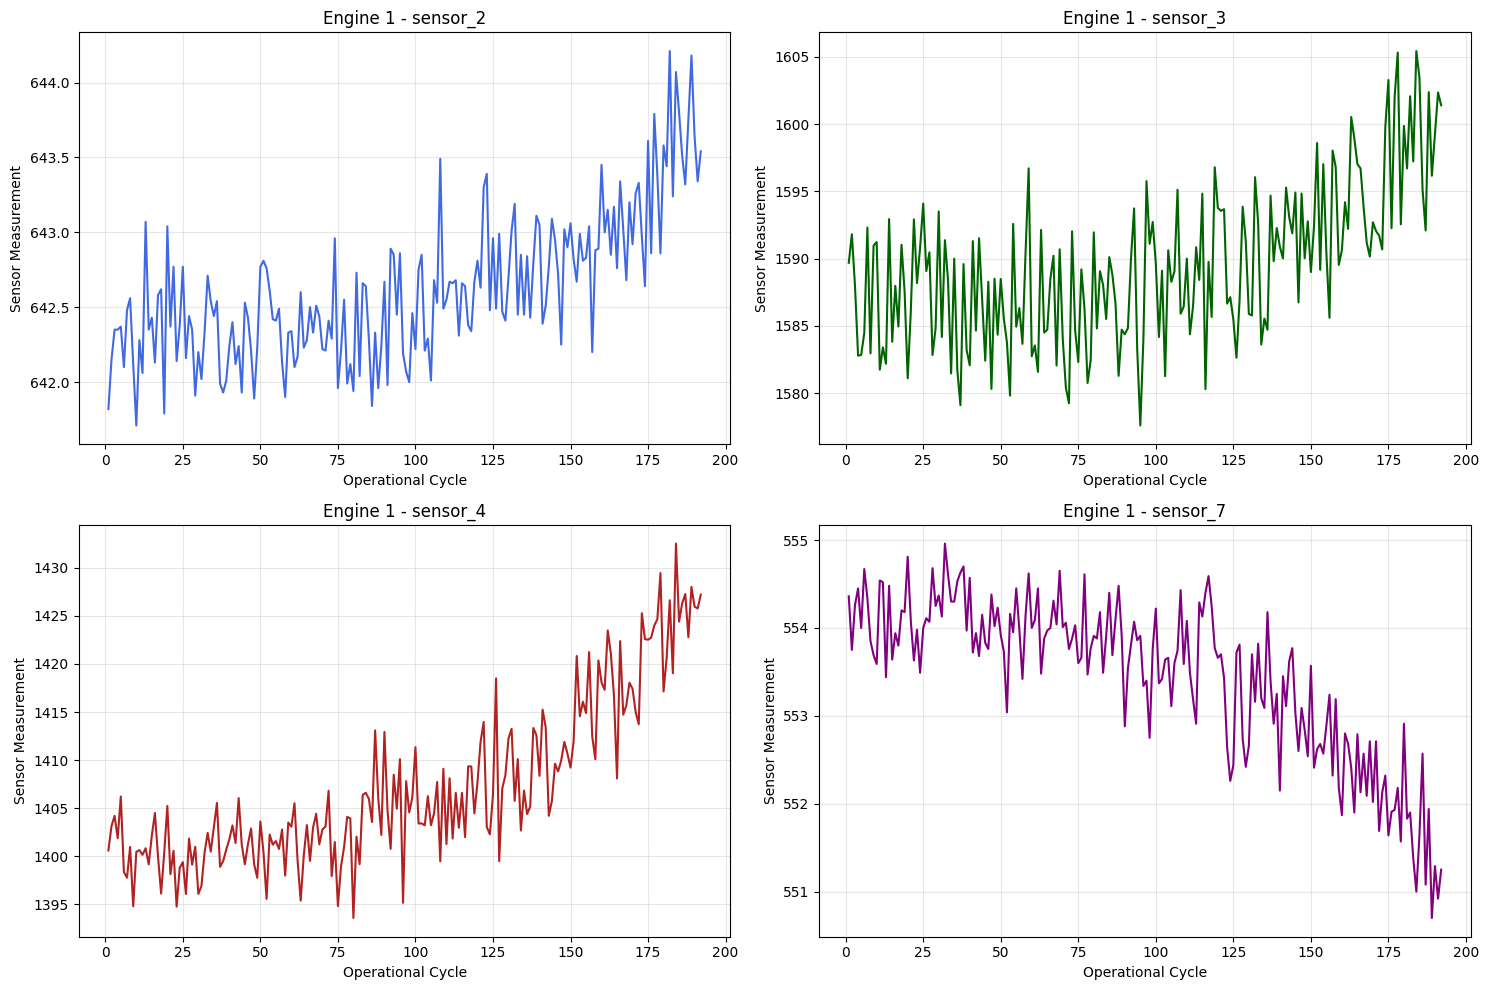

In [34]:
engine = train_df[
    train_df['unit_number'] == 1
]

sensors = [
    'sensor_2',
    'sensor_3',
    'sensor_4',
    'sensor_7'
]

colors = [
    'royalblue',
    'darkgreen',
    'firebrick',
    'purple'
]

fig, axes = plt.subplots(
    2, 2, figsize=(15, 10)
)

for ax, sensor, color in zip(
    axes.flatten(), sensors, colors
):

    ax.plot(
        engine['time_cycles'],
        engine[sensor],
        color=color,
        linewidth=1.5
    )

    ax.set_title(f"Engine 1 - {sensor}")
    ax.set_xlabel("Operational Cycle")
    ax.set_ylabel("Sensor Measurement")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Step 12 – Remaining Useful Life Visualisation

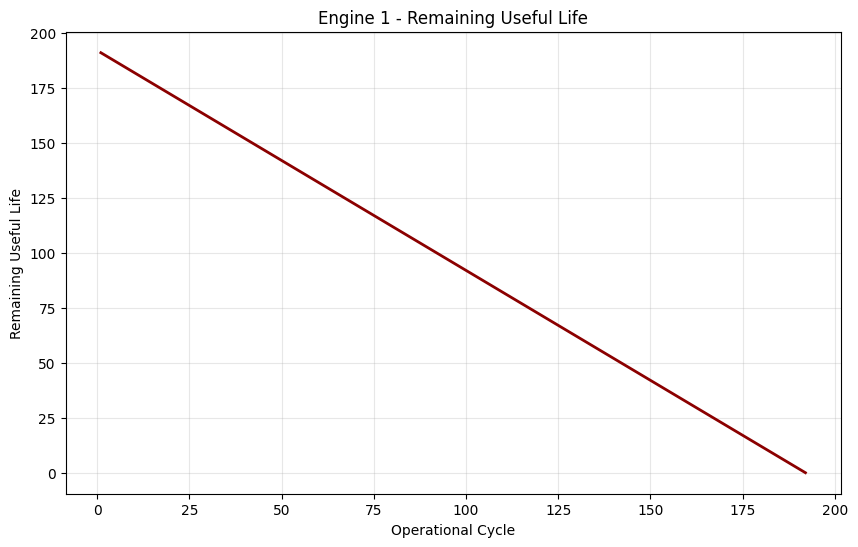

In [35]:
plt.figure(figsize=(10, 6))

plt.plot(
    engine['time_cycles'],
    engine['RUL'],
    color='darkred',
    linewidth=2
)

plt.title("Engine 1 - Remaining Useful Life")
plt.xlabel("Operational Cycle")
plt.ylabel("Remaining Useful Life")
plt.grid(alpha=0.3)
plt.show()

#### Step 13 – Sensor Correlation Analysis

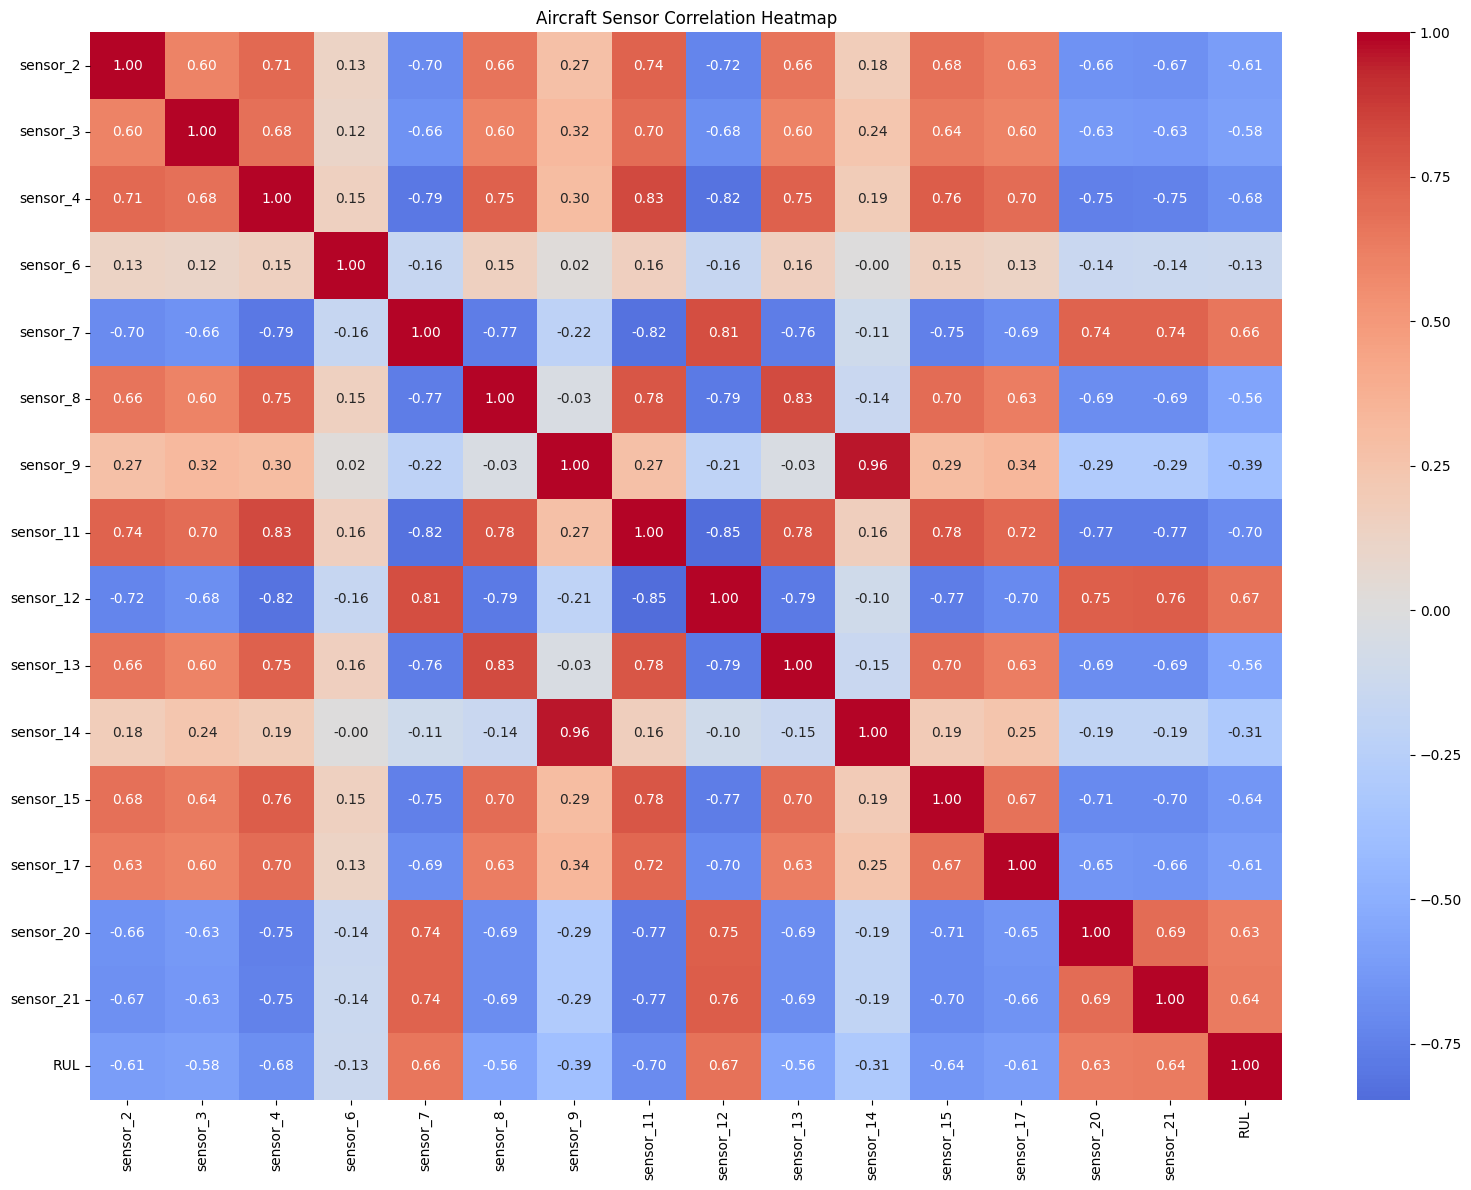

In [36]:
sensor_columns = [
    col for col in train_df.columns
    if col.startswith('sensor_')
    and train_df[col].std() > 0.000001
]

correlation_data = train_df[
    sensor_columns + ['RUL']
]

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title("Aircraft Sensor Correlation Heatmap")
plt.tight_layout()
plt.show()

#### Step 14 - Data Preprocessing

In [37]:
# Training and Validation Data Splitting

engine_ids = train_df['unit_number'].unique()

train_ids, val_ids = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

air_train = train_df[
    train_df['unit_number'].isin(train_ids)
].copy()

air_val = train_df[
    train_df['unit_number'].isin(val_ids)
].copy()

air_test = test_df.copy()

print("Training engines:", len(train_ids))
print("Validation engines:", len(val_ids))
print("Testing engines:", air_test['unit_number'].nunique())

print("\nTraining shape:", air_train.shape)
print("Validation shape:", air_val.shape)
print("Testing shape:", air_test.shape)

Training engines: 80
Validation engines: 20
Testing engines: 100

Training shape: (16561, 27)
Validation shape: (4070, 27)
Testing shape: (13096, 26)


#### Step 15 – Feature Selection

In [38]:
feature_cols = [
    col for col in air_train.columns
    if col.startswith('sensor_')
    or col.startswith('setting_')
]

removed_features = [
    col for col in feature_cols
    if air_train[col].std() <= 0.000001
]

feature_cols = [
    col for col in feature_cols
    if air_train[col].std() > 0.000001
]

print("Removed features:")
print(removed_features)

print("\nSelected features:")
print(feature_cols)

print("\nNumber of selected features:",
      len(feature_cols))

Removed features:
['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

Selected features:
['setting_1', 'setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Number of selected features: 17


#### Step 16 – Feature Standardisation

In [39]:
air_scaler = StandardScaler()

air_train[feature_cols] = air_scaler.fit_transform(
    air_train[feature_cols]
)

air_val[feature_cols] = air_scaler.transform(
    air_val[feature_cols]
)

air_test[feature_cols] = air_scaler.transform(
    air_test[feature_cols]
)

print("Feature standardisation completed.")

display(air_train[feature_cols].head())

Feature standardisation completed.


,setting_1,setting_2,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
192,-0.818512,2.043793,-1.581191,-1.092662,-1.963014,-7.193194,1.318090,-1.221017,-0.471297,-2.294365,1.242127,-0.500147,-0.315944,-1.373754,-1.426246,0.678684,1.564436
193,1.966124,-1.031739,-1.721722,-0.565155,-1.756664,0.139020,1.591518,-1.645675,-0.621789,-1.127747,1.745551,-1.615806,-0.654442,-0.675217,-0.779529,1.345844,1.098895
194,0.824880,1.018616,-2.263772,-0.356453,-1.106382,-7.193194,2.013053,-0.796358,-0.492481,-1.203012,1.582278,-1.476349,-0.169925,-1.648369,-1.426246,1.623827,1.252524
195,1.600926,-1.373465,-2.002785,-1.041719,-1.427619,0.139020,0.999091,-1.645675,-0.326102,-1.654606,1.459824,-2.313093,-0.177072,-1.072476,-1.426246,1.735021,1.975974
196,0.231433,1.360341,-1.902406,-1.883102,-0.709298,-7.193194,1.990267,-0.937911,-0.319923,-1.090114,1.160491,-2.173636,-0.369552,-1.475068,-2.072963,2.013004,1.237627


#### Step 17 – Time-Series Sequence Preparation

In [40]:
sequence_length = 30

def create_sequences(data, features, length):

    X, y = [], []

    for unit in data['unit_number'].unique():

        unit_data = data[
            data['unit_number'] == unit
        ].sort_values('time_cycles')

        values = unit_data[features].values
        targets = unit_data['RUL'].values

        for i in range(len(values) - length + 1):

            X.append(values[i:i + length])

            y.append(targets[i + length - 1])

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.float32)
    )


X_air_train, y_air_train = create_sequences(
    air_train,
    feature_cols,
    sequence_length
)

X_air_val, y_air_val = create_sequences(
    air_val,
    feature_cols,
    sequence_length
)

print("Training input shape:", X_air_train.shape)
print("Training target shape:", y_air_train.shape)

print("\nValidation input shape:", X_air_val.shape)
print("Validation target shape:", y_air_val.shape)

Training input shape: (14241, 30, 17)
Training target shape: (14241,)

Validation input shape: (3490, 30, 17)
Validation target shape: (3490,)


#### Step 18 – Prepare Testing Sequences

In [41]:
X_air_test = []
test_engine_ids = []

for unit in sorted(air_test['unit_number'].unique()):

    unit_data = air_test[
        air_test['unit_number'] == unit
    ].sort_values('time_cycles')

    values = unit_data[feature_cols].values

    if len(values) < sequence_length:

        padding = np.repeat(
            values[:1],
            sequence_length - len(values),
            axis=0
        )

        values = np.concatenate(
            [padding, values],
            axis=0
        )

    X_air_test.append(
        values[-sequence_length:]
    )

    test_engine_ids.append(unit)

X_air_test = np.array(
    X_air_test,
    dtype=np.float32
)

y_air_test = rul_df['RUL'].values[
    np.array(test_engine_ids) - 1
]

print("Testing input shape:", X_air_test.shape)
print("Testing target shape:", y_air_test.shape)

Testing input shape: (100, 30, 17)
Testing target shape: (100,)


#### Step 19 - Model Development

In [42]:
# Simple RNN Model Development

rnn_model = Sequential([

    Input(shape=(
        sequence_length,
        len(feature_cols)
    )),

    SimpleRNN(
        64,
        activation='tanh'
    ),

    Dense(
        32,
        activation='relu'
    ),

    Dense(
        1,
        activation='softplus'
    )
])

rnn_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,361 (28.75 KB)

 Trainable params: 7,361 (28.75 KB)

 Non-trainable params: 0 (0.00 B)

#### Step 20 – Train the Simple RNN

In [43]:
rnn_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

rnn_history = rnn_model.fit(

    X_air_train,
    y_air_train,

    validation_data=(
        X_air_val,
        y_air_val
    ),

    epochs=30,
    batch_size=64,

    callbacks=[rnn_early_stop],

    verbose=1
)

Epoch 1/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 7629.2153 - mae: 67.1970 - val_loss: 2632.8406 - val_mae: 38.3719
Epoch 2/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 2218.1887 - mae: 34.7129 - val_loss: 1514.0455 - val_mae: 30.2119
Epoch 3/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 1711.3959 - mae: 30.7807 - val_loss: 984.5594 - val_mae: 24.6698
Epoch 4/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 1507.4479 - mae: 27.8109 - val_loss: 914.1562 - val_mae: 22.8561
Epoch 5/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 1436.3994 - mae: 26.3595 - val_loss: 892.8118 - val_mae: 22.1226
Epoch 6/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 1415.2120 - mae: 25.9906 - val_loss: 880.4708 - val_mae: 21.8318
Epoch 7/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 1402.5084 - mae: 25.8283 - val_loss: 868.1932 - val_mae: 21.5562
Epoch 8/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 1392.1183 - mae: 25.6990 - val_loss: 855.9748 - val_mae: 21

#### Step 21 – Simple RNN Learning Curves

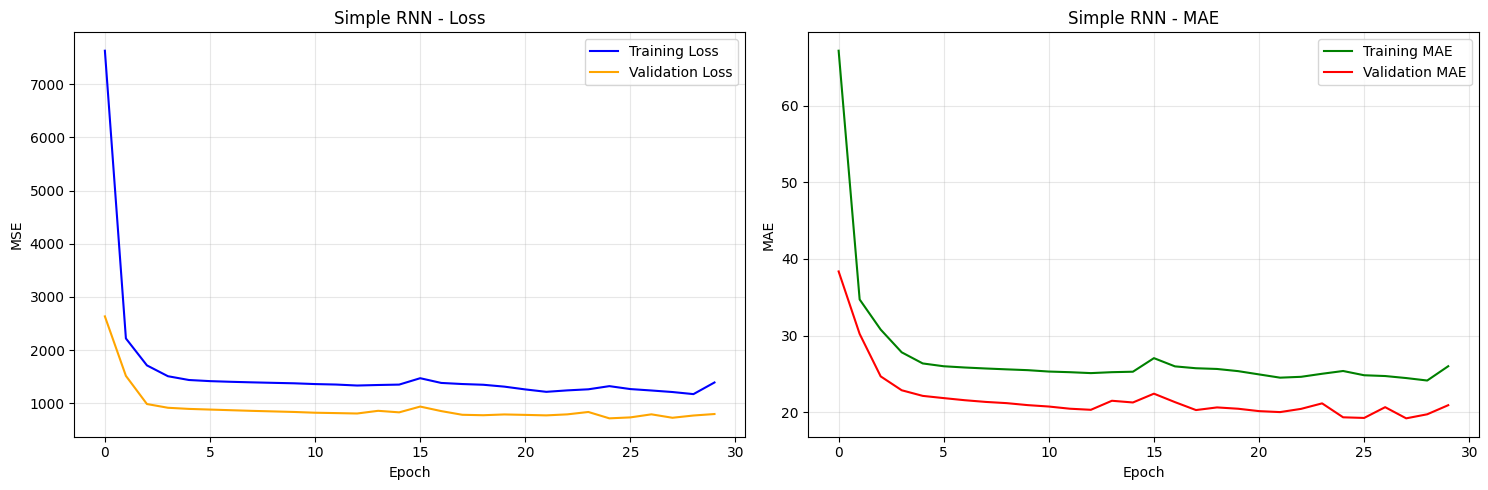

In [44]:
fig, axes = plt.subplots(
    1, 2, figsize=(15, 5)
)

axes[0].plot(
    rnn_history.history['loss'],
    label='Training Loss',
    color='blue'
)

axes[0].plot(
    rnn_history.history['val_loss'],
    label='Validation Loss',
    color='orange'
)

axes[0].set_title("Simple RNN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    rnn_history.history['mae'],
    label='Training MAE',
    color='green'
)

axes[1].plot(
    rnn_history.history['val_mae'],
    label='Validation MAE',
    color='red'
)

axes[1].set_title("Simple RNN - MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MAE")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Step 22 – LSTM Model Development

In [45]:
lstm_model = Sequential([

    Input(shape=(
        sequence_length,
        len(feature_cols)
    )),

    LSTM(
        64,
        return_sequences=True
    ),

    Dropout(0.2),

    LSTM(32),

    Dropout(0.2),

    Dense(
        32,
        activation='relu'
    ),

    Dense(
        1,
        activation='softplus'
    )
])

lstm_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        20,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,497 (134.75 KB)

 Trainable params: 34,497 (134.75 KB)

 Non-trainable params: 0 (0.00 B)

#### Step 23 – Train the LSTM Model

In [46]:
lstm_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

lstm_history = lstm_model.fit(

    X_air_train,
    y_air_train,

    validation_data=(
        X_air_val,
        y_air_val
    ),

    epochs=30,
    batch_size=64,

    callbacks=[lstm_early_stop],

    verbose=1
)

Epoch 1/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - loss: 7741.4966 - mae: 65.9304 - val_loss: 2402.3701 - val_mae: 33.6274
Epoch 2/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 10s 46ms/step - loss: 1855.2009 - mae: 28.0484 - val_loss: 736.3921 - val_mae: 18.8748
Epoch 3/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 9s 39ms/step - loss: 1204.1163 - mae: 23.1664 - val_loss: 600.3077 - val_mae: 17.0343
Epoch 4/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 10s 46ms/step - loss: 1070.5278 - mae: 21.8740 - val_loss: 598.8178 - val_mae: 17.5002
Epoch 5/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - loss: 924.1896 - mae: 20.4382 - val_loss: 640.8737 - val_mae: 17.9257
Epoch 6/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 814.0995 - mae: 19.2436 - val_loss: 639.0303 - val_mae: 17.5611
Epoch 7/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - loss: 718.5043 - mae: 18.1243 - val_loss: 720.3771 - val_mae: 18.3412
Epoch 8/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 11s 48ms/step - loss: 626.2020 - mae: 16.9287 - val_loss: 811.5928 - val_ma

#### Step 24 – LSTM Learning Curves

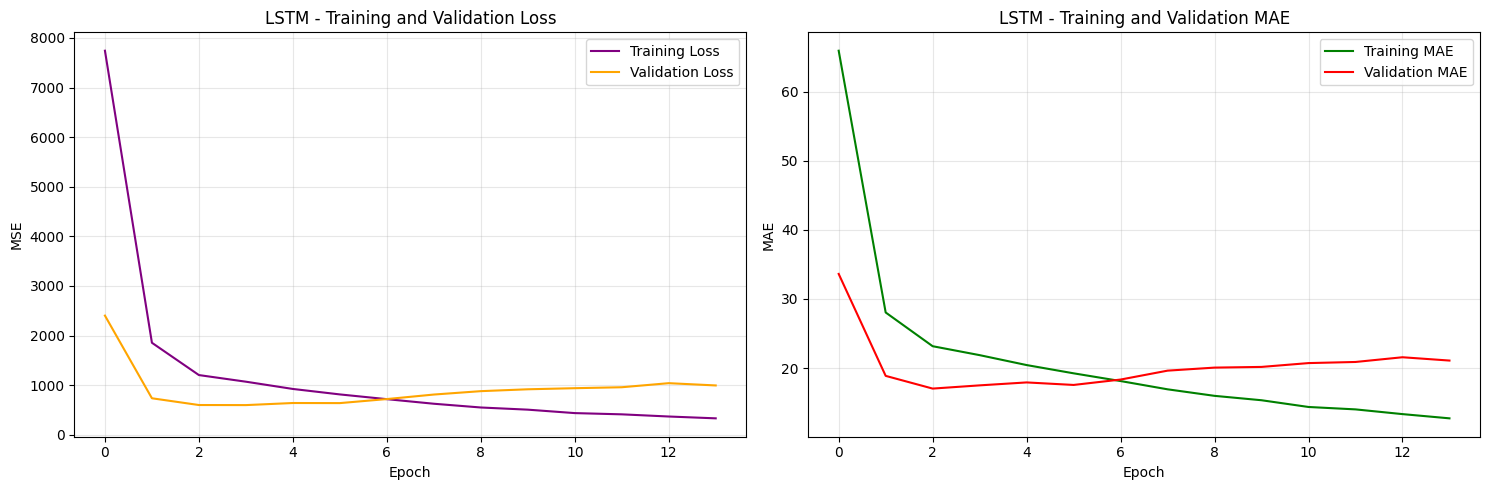

In [47]:
fig, axes = plt.subplots(
    1, 2, figsize=(15, 5)
)

axes[0].plot(
    lstm_history.history['loss'],
    label='Training Loss',
    color='purple'
)

axes[0].plot(
    lstm_history.history['val_loss'],
    label='Validation Loss',
    color='orange'
)

axes[0].set_title("LSTM - Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    lstm_history.history['mae'],
    label='Training MAE',
    color='green'
)

axes[1].plot(
    lstm_history.history['val_mae'],
    label='Validation MAE',
    color='red'
)

axes[1].set_title("LSTM - Training and Validation MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MAE")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Step 25 – Compare Model Learning Behaviour

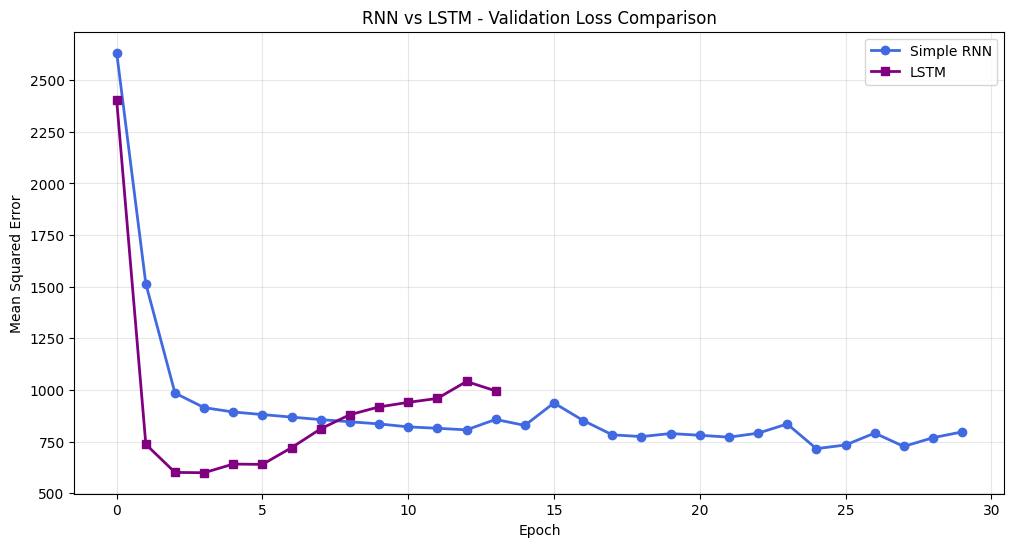

Best RNN Validation Loss: 715.3340454101562
Best LSTM Validation Loss: 598.8178100585938
Best RNN Epoch: 25
Best LSTM Epoch: 4


In [48]:
plt.figure(figsize=(12, 6))

plt.plot(
    rnn_history.history['val_loss'],
    label='Simple RNN',
    color='royalblue',
    linewidth=2,
    marker='o'
)

plt.plot(
    lstm_history.history['val_loss'],
    label='LSTM',
    color='purple',
    linewidth=2,
    marker='s'
)

plt.title("RNN vs LSTM - Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Best RNN Validation Loss:",
      min(rnn_history.history['val_loss']))

print("Best LSTM Validation Loss:",
      min(lstm_history.history['val_loss']))

print("Best RNN Epoch:",
      np.argmin(rnn_history.history['val_loss']) + 1)

print("Best LSTM Epoch:",
      np.argmin(lstm_history.history['val_loss']) + 1)

#### Step 26 – Generate RUL Predictions

In [49]:
rnn_predictions = rnn_model.predict(
    X_air_test,
    verbose=0
).flatten()

lstm_predictions = lstm_model.predict(
    X_air_test,
    verbose=0
).flatten()

prediction_df = pd.DataFrame({
    'Engine ID': test_engine_ids,
    'Actual RUL': y_air_test,
    'RNN Predicted RUL': rnn_predictions,
    'LSTM Predicted RUL': lstm_predictions
})

display(prediction_df.head(15).round(2))

,Engine ID,Actual RUL,RNN Predicted RUL,LSTM Predicted RUL
0,1,112,162.139999,152.220001
1,2,98,128.529999,155.339996
2,3,69,53.060001,50.230000
3,4,82,118.610001,86.160004
4,5,91,134.339996,126.089996
5,6,93,116.800003,124.779999
6,7,91,107.430000,94.940002
7,8,95,119.970001,106.059998
8,9,111,146.899994,166.990005
9,10,96,105.779999,97.750000


#### Step 27 – Model Performance Evaluation

In [50]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(actual, predicted):

    return {
        'MAE': mean_absolute_error(actual, predicted),
        'MSE': mean_squared_error(actual, predicted),
        'RMSE': np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        'R2 Score': r2_score(actual, predicted)
    }

results = pd.DataFrame([

    evaluate_model(
        y_air_test,
        rnn_predictions
    ),

    evaluate_model(
        y_air_test,
        lstm_predictions
    )

], index=['Simple RNN', 'LSTM'])

display(results.round(4))

,MAE,MSE,RMSE,R2 Score
Simple RNN,17.9632,627.4072,25.0481,0.6367
LSTM,16.8332,573.6817,23.9517,0.6678


#### Step 28 – Baseline Model Comparison

In [51]:
baseline_predictions = np.full(
    len(y_air_test),
    np.mean(y_air_train)
)

results.loc['Mean Baseline'] = evaluate_model(
    y_air_test,
    baseline_predictions
)

display(results.round(4))

,MAE,MSE,RMSE,R2 Score
Simple RNN,17.9632,627.4072,25.0481,0.6367
LSTM,16.8332,573.6817,23.9517,0.6678
Mean Baseline,36.6155,2096.7742,45.7905,-0.2142


#### Step 29 – Model Performance Visualisation

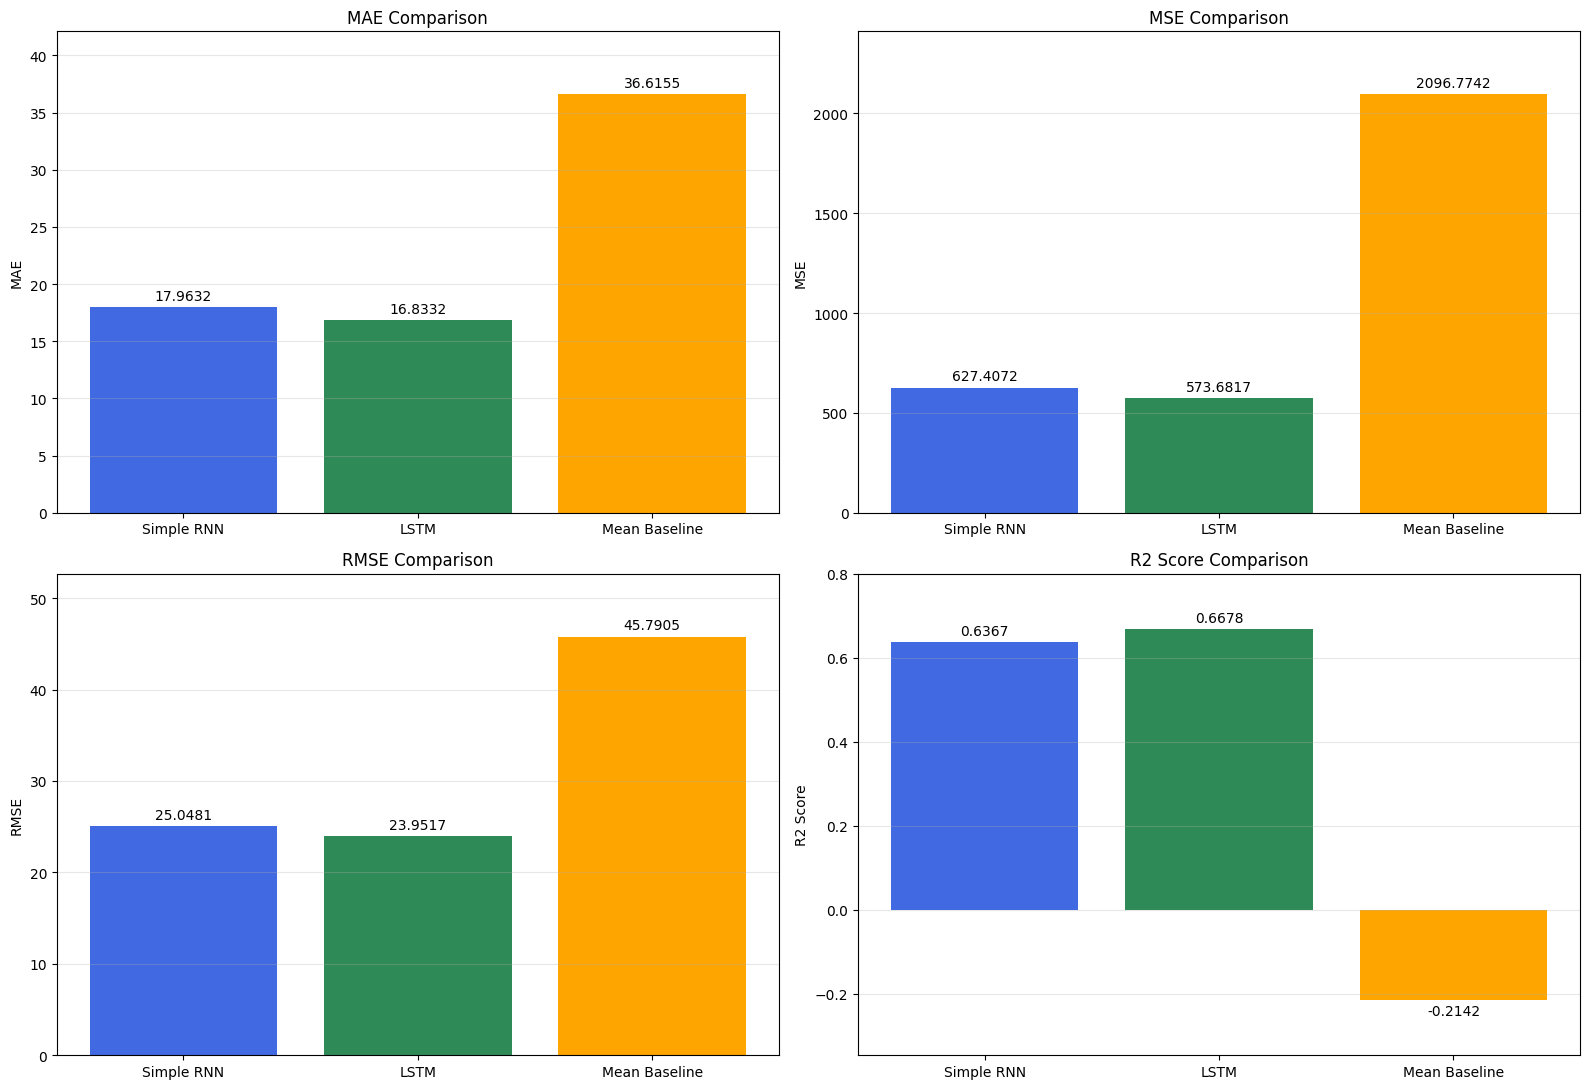

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

metrics = [
    'MAE',
    'MSE',
    'RMSE',
    'R2 Score'
]

colors = [
    'royalblue',
    'seagreen',
    'orange'
]

for ax, metric in zip(axes.flatten(), metrics):

    bars = ax.bar(
        results.index,
        results[metric],
        color=colors
    )

    ax.bar_label(
        bars,
        fmt='%.4f',
        padding=3
    )

    ax.set_title(metric + " Comparison")
    ax.set_ylabel(metric)
    ax.grid(axis='y', alpha=0.3)
    ax.margins(y=0.15)

plt.tight_layout()
plt.show()

#### Step 30 – Actual versus Predicted RUL

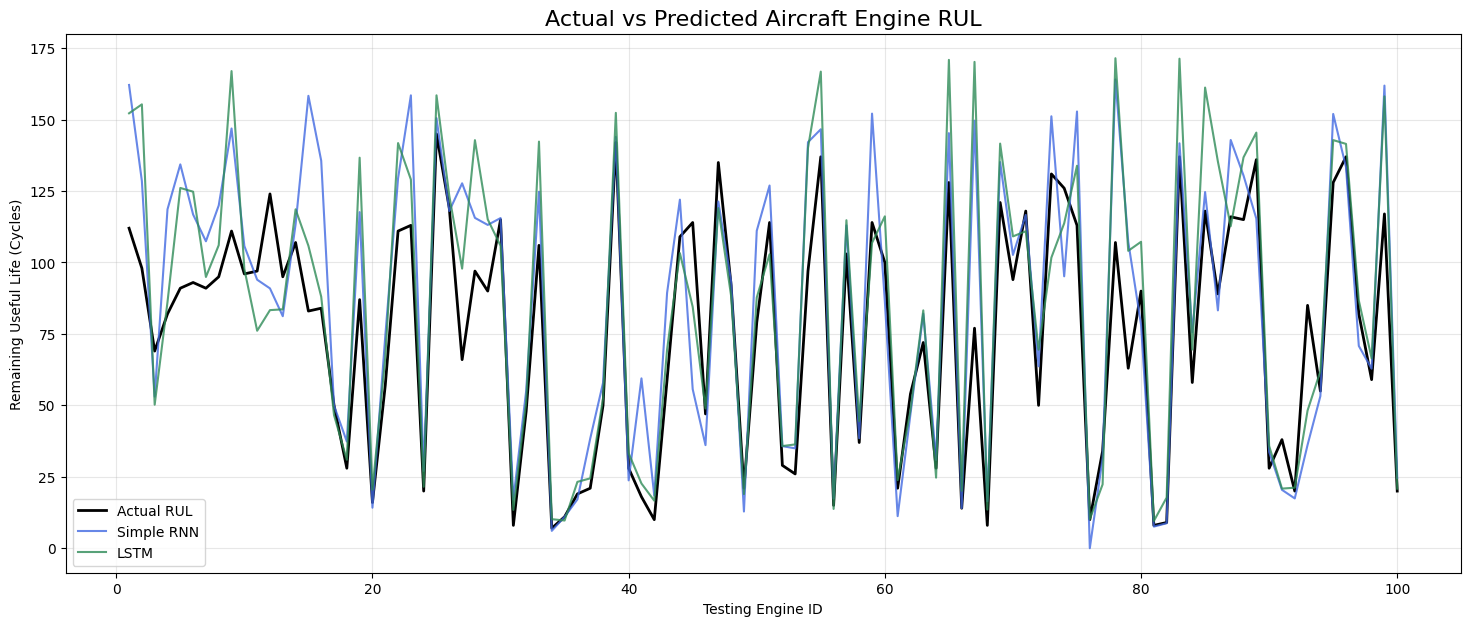

In [53]:
plt.figure(figsize=(18, 7))

plt.plot(
    test_engine_ids,
    y_air_test,
    label='Actual RUL',
    color='black',
    linewidth=2
)

plt.plot(
    test_engine_ids,
    rnn_predictions,
    label='Simple RNN',
    color='royalblue',
    alpha=0.8
)

plt.plot(
    test_engine_ids,
    lstm_predictions,
    label='LSTM',
    color='seagreen',
    alpha=0.8
)

plt.title(
    "Actual vs Predicted Aircraft Engine RUL",
    fontsize=16
)

plt.xlabel("Testing Engine ID")
plt.ylabel("Remaining Useful Life (Cycles)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Step 31 – Prediction Scatter Plot

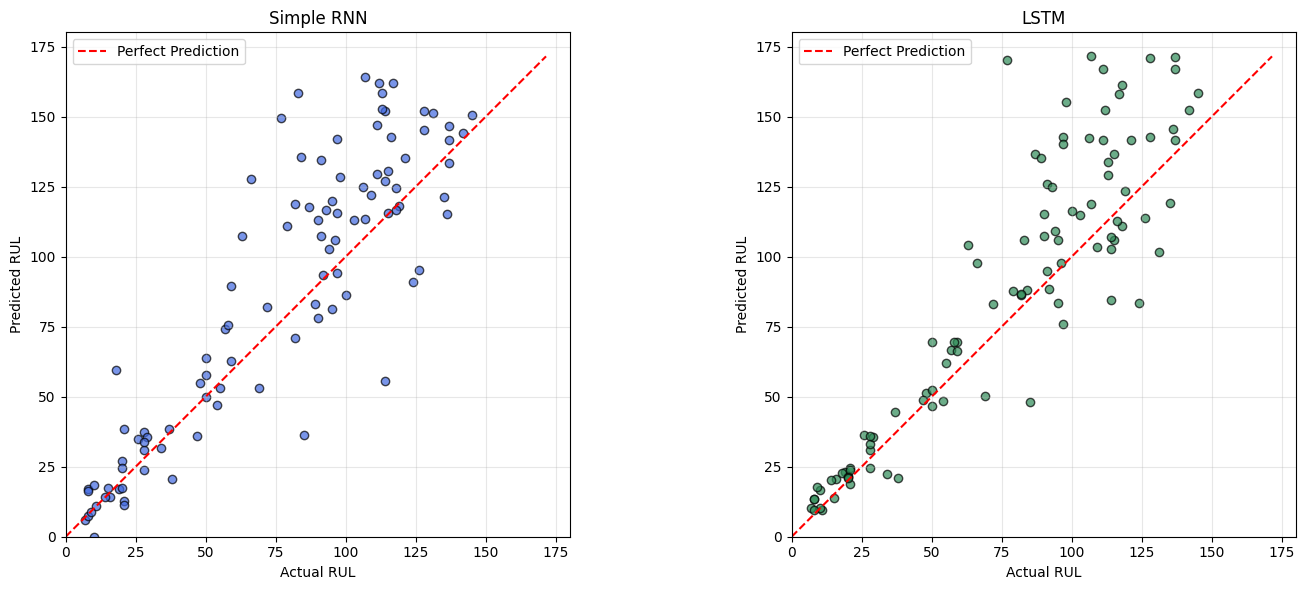

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

maximum = max(
    y_air_test.max(),
    rnn_predictions.max(),
    lstm_predictions.max()
)

for ax, predictions, model_name, color in zip(
    axes,
    [rnn_predictions, lstm_predictions],
    ['Simple RNN', 'LSTM'],
    ['royalblue', 'seagreen']
):

    ax.scatter(
        y_air_test,
        predictions,
        color=color,
        alpha=0.7,
        edgecolor='black'
    )

    ax.plot(
        [0, maximum],
        [0, maximum],
        'r--',
        label='Perfect Prediction'
    )

    ax.set_title(model_name)
    ax.set_xlabel("Actual RUL")
    ax.set_ylabel("Predicted RUL")
    ax.set_xlim(0, maximum * 1.05)
    ax.set_ylim(0, maximum * 1.05)
    ax.set_aspect('equal')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Step 32 – Residual Error Analysis

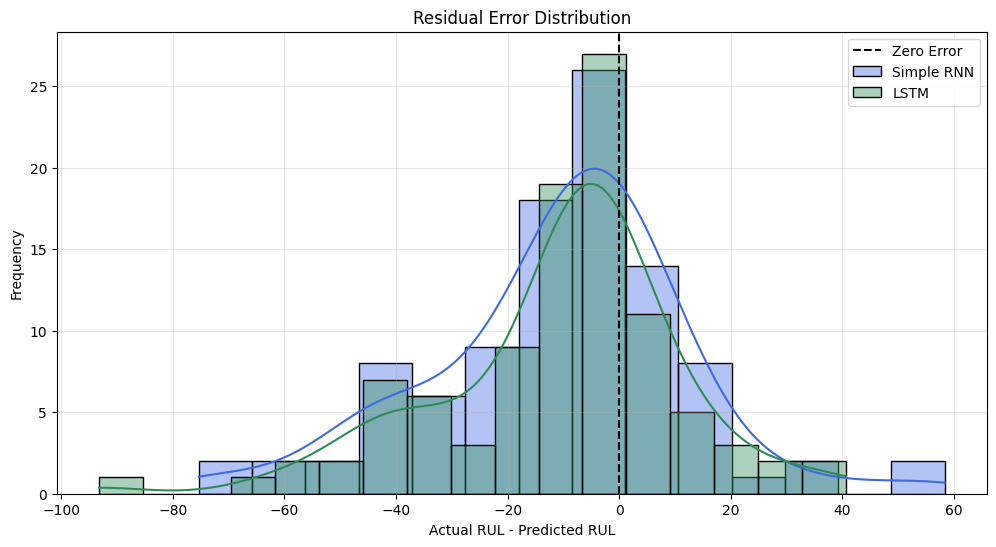

RNN Mean Residual: -10.6365
LSTM Mean Residual: -10.6616
RNN Residual Standard Deviation: 22.6776
LSTM Residual Standard Deviation: 21.4479


In [55]:
rnn_residuals = y_air_test - rnn_predictions
lstm_residuals = y_air_test - lstm_predictions

plt.figure(figsize=(12, 6))

sns.histplot(
    rnn_residuals,
    kde=True,
    label='Simple RNN',
    color='royalblue',
    alpha=0.4
)

sns.histplot(
    lstm_residuals,
    kde=True,
    label='LSTM',
    color='seagreen',
    alpha=0.4
)

plt.axvline(
    0,
    color='black',
    linestyle='--',
    label='Zero Error'
)

plt.title("Residual Error Distribution")
plt.xlabel("Actual RUL - Predicted RUL")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("RNN Mean Residual:",
      round(np.mean(rnn_residuals), 4))

print("LSTM Mean Residual:",
      round(np.mean(lstm_residuals), 4))

print("RNN Residual Standard Deviation:",
      round(np.std(rnn_residuals), 4))

print("LSTM Residual Standard Deviation:",
      round(np.std(lstm_residuals), 4))

#### Step 33 – NASA Asymmetric Scoring Function

In [56]:
def nasa_score(actual, predicted):

    error = predicted - actual

    scores = np.where(
        error < 0,
        np.expm1(-error / 13),
        np.expm1(error / 10)
    )

    return np.sum(scores)


results.loc['Simple RNN', 'NASA Score'] = nasa_score(
    y_air_test,
    rnn_predictions
)

results.loc['LSTM', 'NASA Score'] = nasa_score(
    y_air_test,
    lstm_predictions
)

results.loc['Mean Baseline', 'NASA Score'] = nasa_score(
    y_air_test,
    baseline_predictions
)

display(results.round(4))

,MAE,MSE,RMSE,R2 Score,NASA Score
Simple RNN,17.9632,627.4072,25.0481,0.6367,5460.0350
LSTM,16.8332,573.6817,23.9517,0.6678,13490.5610
Mean Baseline,36.6155,2096.7742,45.7905,-0.2142,73242.9112


#### Step 33.1 – NASA Score Visualisation

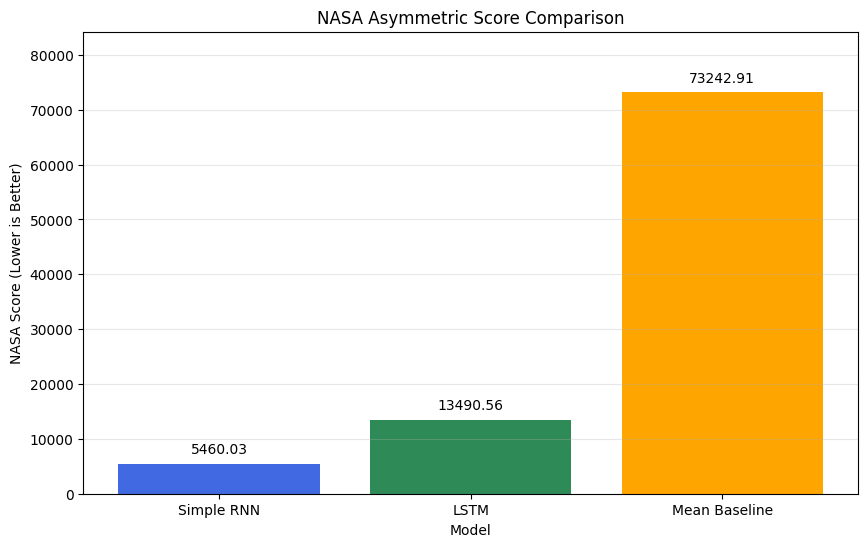

In [57]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    results.index,
    results['NASA Score'],
    color=['royalblue', 'seagreen', 'orange']
)

plt.bar_label(
    bars,
    fmt='%.2f',
    padding=5
)

plt.title("NASA Asymmetric Score Comparison")
plt.xlabel("Model")
plt.ylabel("NASA Score (Lower is Better)")
plt.grid(axis='y', alpha=0.3)
plt.margins(y=0.15)
plt.show()

#### Step 34 – Temporal Degradation Pattern Analysis

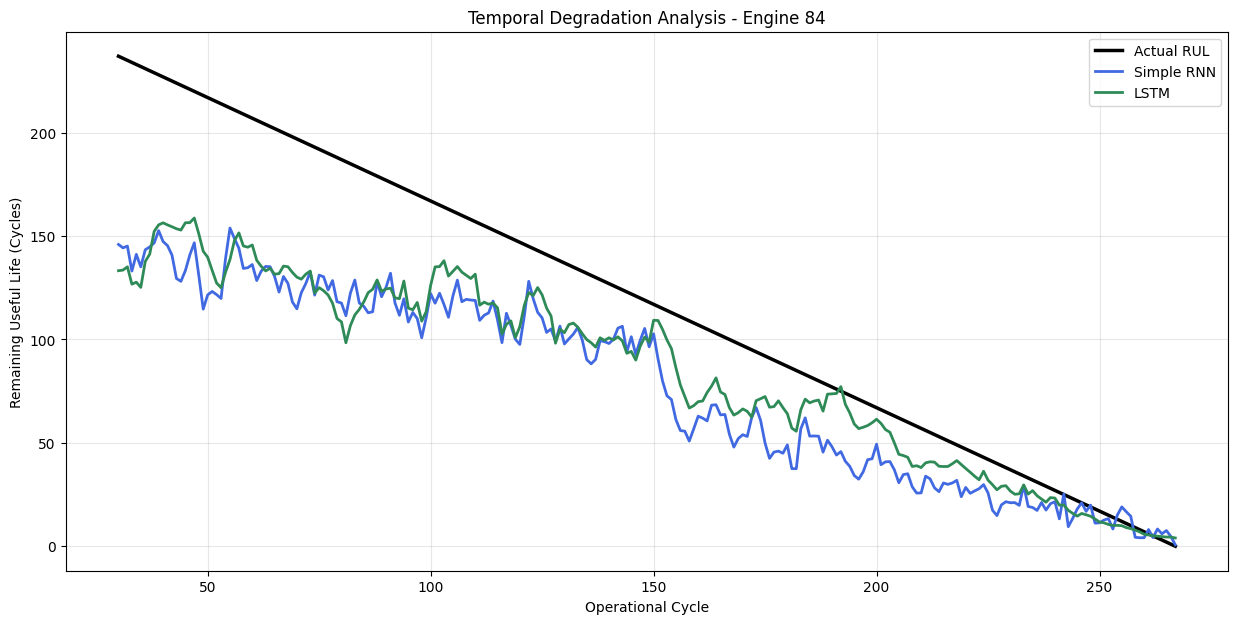

In [58]:
selected_engine = val_ids[0]

validation_engine = air_val[
    air_val['unit_number'] == selected_engine
].sort_values('time_cycles')

X_engine, y_engine = create_sequences(
    validation_engine,
    feature_cols,
    sequence_length
)

engine_cycles = validation_engine[
    'time_cycles'
].values[sequence_length - 1:]

rnn_engine_predictions = rnn_model.predict(
    X_engine,
    verbose=0
).flatten()

lstm_engine_predictions = lstm_model.predict(
    X_engine,
    verbose=0
).flatten()

plt.figure(figsize=(15, 7))

plt.plot(
    engine_cycles,
    y_engine,
    label='Actual RUL',
    color='black',
    linewidth=2.5
)

plt.plot(
    engine_cycles,
    rnn_engine_predictions,
    label='Simple RNN',
    color='royalblue',
    linewidth=2
)

plt.plot(
    engine_cycles,
    lstm_engine_predictions,
    label='LSTM',
    color='seagreen',
    linewidth=2
)

plt.title(
    f"Temporal Degradation Analysis - Engine {selected_engine}"
)

plt.xlabel("Operational Cycle")
plt.ylabel("Remaining Useful Life (Cycles)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Step 34.1 – Individual Engine Performance

In [59]:
engine_results = pd.DataFrame([

    evaluate_model(
        y_engine,
        rnn_engine_predictions
    ),

    evaluate_model(
        y_engine,
        lstm_engine_predictions
    )

], index=['Simple RNN', 'LSTM'])

print("Selected Validation Engine:", selected_engine)

display(engine_results.round(4))

Selected Validation Engine: 84


,MAE,MSE,RMSE,R2 Score
Simple RNN,40.9188,2329.3274,48.2631,0.5065
LSTM,33.7367,1868.6044,43.2274,0.6041


#### **Interpretation of Temporal Degradation Analysis**

The temporal degradation analysis was performed using
validation engine 84.

The Simple RNN achieved an MAE of 40.9188, RMSE of
48.2631 and an R² score of 0.5065.

The LSTM achieved an MAE of 33.7367, RMSE of 43.2274
and an R² score of 0.6041.

These results indicate that the LSTM captured the temporal
degradation pattern more effectively for the selected
validation engine.

However, both models produced noticeable prediction errors.
The findings from one engine cannot represent the
performance across all aircraft engines.

#### Step 35 – Final Model Performance Summary

In [60]:
neural_results = results.loc[
    ['Simple RNN', 'LSTM']
]

best_model = neural_results['RMSE'].idxmin()

rnn_rmse = results.loc['Simple RNN', 'RMSE']
lstm_rmse = results.loc['LSTM', 'RMSE']
baseline_rmse = results.loc['Mean Baseline', 'RMSE']

rmse_improvement = (
    (rnn_rmse - lstm_rmse) / rnn_rmse
) * 100

mae_improvement = (
    (
        results.loc['Simple RNN', 'MAE']
        - results.loc['LSTM', 'MAE']
    )
    / results.loc['Simple RNN', 'MAE']
) * 100

baseline_improvement = (
    (
        baseline_rmse
        - results.loc[best_model, 'RMSE']
    )
    / baseline_rmse
) * 100

print("=" * 65)
print("FINAL AIRCRAFT RUL PREDICTION PERFORMANCE")
print("=" * 65)

display(results.round(4))

print("\nBest Neural Network Model:", best_model)

print("\nBest Model MAE:",
      round(results.loc[best_model, 'MAE'], 4))

print("Best Model RMSE:",
      round(results.loc[best_model, 'RMSE'], 4))

print("Best Model R2 Score:",
      round(results.loc[best_model, 'R2 Score'], 4))

print("Best Model NASA Score:",
      round(results.loc[best_model, 'NASA Score'], 4))

print("\nLSTM MAE Improvement over RNN:",
      round(mae_improvement, 2), "%")

print("LSTM RMSE Improvement over RNN:",
      round(rmse_improvement, 2), "%")

print("Best Model RMSE Improvement over Baseline:",
      round(baseline_improvement, 2), "%")

print("=" * 65)

FINAL AIRCRAFT RUL PREDICTION PERFORMANCE


,MAE,MSE,RMSE,R2 Score,NASA Score
Simple RNN,17.9632,627.4072,25.0481,0.6367,5460.0350
LSTM,16.8332,573.6817,23.9517,0.6678,13490.5610
Mean Baseline,36.6155,2096.7742,45.7905,-0.2142,73242.9112



Best Neural Network Model: LSTM

Best Model MAE: 16.8332
Best Model RMSE: 23.9517
Best Model R2 Score: 0.6678
Best Model NASA Score: 13490.561

LSTM MAE Improvement over RNN: 6.29 %
LSTM RMSE Improvement over RNN: 4.38 %
Best Model RMSE Improvement over Baseline: 47.69 %


#### Step 36 – Critical Discussion

The LSTM achieved better conventional regression performance
than the Simple RNN, with an MAE of 16.8332, RMSE of
23.9517 and an R² score of 0.6678.

The LSTM reduced RMSE by 4.38% compared with the Simple
RNN and by 47.69% compared with the mean baseline model.

However, the Simple RNN achieved a lower NASA asymmetric
score of 5460.035 compared with 13490.561 for the LSTM.
This indicates that the Simple RNN performed better under
the asymmetric penalty for RUL prediction errors.

Both models demonstrated a tendency to overestimate RUL,
with mean residuals of -10.6365 for the Simple RNN and
-10.6616 for the LSTM.

The LSTM learning curves also indicated overfitting.
Early stopping restored the best model weights, which
occurred at epoch 4.

Overall, LSTM achieved better conventional regression
performance, while Simple RNN achieved better performance
under the NASA scoring criterion. Both evaluation
perspectives are important when assessing predictive
maintenance models.

#### Step 37 – Limitations and Future Improvements

#### **Limitations**

- The NASA C-MAPSS dataset contains simulated aircraft
  engine degradation data.
- The FD001 subset represents only one operating condition
  and one fault mode.
- The fixed sequence length of 30 cycles may not capture
  all long-term degradation patterns.
- The LSTM model demonstrates some overfitting.
- The models have not been validated in real aircraft
  operating environments.

#### **Future Improvements**

- Investigate additional C-MAPSS dataset subsets.
- Optimise model hyperparameters and sequence lengths.
- Apply additional regularisation techniques.
- Explore GRU and Transformer-based architectures.
- Investigate prediction uncertainty.
- Validate the models using real-world maintenance data.

#### Step 38 – Part B Discussion

This study investigated aircraft engine predictive
maintenance using Simple RNN and LSTM models with the
NASA C-MAPSS FD001 dataset.

Both models were trained using historical sensor
measurements arranged into sequences of 30 operational
cycles to predict Remaining Useful Life (RUL).

The LSTM achieved better predictive performance, with
an MAE of 16.8332, RMSE of 23.9517, and an R² score
of 0.6678.

The results demonstrate the potential of recurrent
neural networks to support predictive maintenance
and reduce unexpected equipment failures.

However, further model optimisation and real-world
validation are necessary before practical deployment.

#### Step 39 – Save Models and Results

In [61]:
import os
import joblib

output_path = (
    "/content/drive/MyDrive/"
    "Aircraft_Predictive_Maintenance_Results"
)

os.makedirs(output_path, exist_ok=True)

# Save trained models
rnn_model.save(
    os.path.join(output_path, "aircraft_rnn.keras")
)

lstm_model.save(
    os.path.join(output_path, "aircraft_lstm.keras")
)

# Save preprocessing scaler
joblib.dump(
    air_scaler,
    os.path.join(output_path, "aircraft_scaler.pkl")
)

# Save model configuration
joblib.dump(
    {
        "feature_columns": feature_cols,
        "sequence_length": sequence_length
    },
    os.path.join(output_path, "aircraft_configuration.pkl")
)

# Save evaluation results
results.to_csv(
    os.path.join(output_path, "model_comparison.csv")
)

# Save predictions
prediction_df.to_csv(
    os.path.join(output_path, "rul_predictions.csv"),
    index=False
)

print("All models and results saved successfully.")

print("\nSaved files:")

for filename in os.listdir(output_path):
    print(filename)

All models and results saved successfully.

Saved files:
aircraft_rnn.keras
aircraft_lstm.keras
aircraft_scaler.pkl
aircraft_configuration.pkl
model_comparison.csv
rul_predictions.csv


### **Overall Conclusion**

This project investigated the application of representation
learning and recurrent neural networks to predictive
maintenance within transportation systems.

In Part A, the MetroPT-3 train sensor dataset was analysed
using Principal Component Analysis, a Linear Autoencoder
and a Self-Organising Map.

PCA retained 59.14% of the original variance using two
principal components. PCA and the Linear Autoencoder
achieved similar reconstruction errors of 0.388070 and
0.388751, respectively.

The SOM provided additional insights into sensor data
organisation, while anomaly detection identified 473
potentially unusual observations, representing 4.73%
of the testing dataset.

In Part B, Simple RNN and LSTM models were developed
using the NASA C-MAPSS FD001 aircraft engine dataset
to predict Remaining Useful Life.

The LSTM achieved an MAE of 16.8332, RMSE of 23.9517
and an R² score of 0.6678. It reduced RMSE by 47.69%
compared with the mean baseline model.

However, the Simple RNN achieved a lower NASA asymmetric
score, demonstrating the importance of considering
different evaluation criteria in predictive maintenance.

The findings demonstrate the potential of machine learning
and neural networks to identify unusual operating patterns,
predict equipment degradation and support data-driven
maintenance planning.

Nevertheless, further model optimisation, fault validation,
uncertainty estimation and real-world evaluation are
required before practical deployment.

### **References**

1. Jolliffe, I.T. and Cadima, J. (2016).
   Principal component analysis: a review and recent
   developments. Philosophical Transactions of the Royal
   Society A, 374(2065), 20150202.

2. Baldi, P. and Hornik, K. (1989).
   Neural networks and principal component analysis:
   Learning from examples without local minima.
   Neural Networks, 2(1), pp. 53–58.

3. Kohonen, T. (1990).
   The self-organizing map.
   Proceedings of the IEEE, 78(9), pp. 1464–1480.

4. Hochreiter, S. and Schmidhuber, J. (1997).
   Long short-term memory.
   Neural Computation, 9(8), pp. 1735–1780.

5. Saxena, A., Goebel, K., Simon, D. and Eklund, N. (2008).
   Damage propagation modeling for aircraft engine
   run-to-failure simulation.
   International Conference on Prognostics and
   Health Management.

6. UCI Machine Learning Repository.
   MetroPT-3 Dataset.
   https://archive.ics.uci.edu/dataset/791/metropt+3+dataset

7. NASA Prognostics Center of Excellence.
   C-MAPSS Turbofan Engine Degradation Simulation Dataset.

8. TensorFlow Documentation.
   https://www.tensorflow.org/

9. Scikit-learn Documentation.
   https://scikit-learn.org/